# TrustEdge-CXR — Review 2 training notebook

Trains the improved pneumonia screener end to end on a free Colab GPU:

| Step | What it does | Gap closed | T4 time |
|---|---|---|---|
| 1 · prepare_data | patient-level train/val split (official test kept), CLAHE cache | G2 | ~1 min |
| 2 · teacher | RAD-DINO (86.6 M params, 882k CXRs) embeddings → linear probe + MLP teacher | G1, G2 | ~5 min |
| 3 · train_student | MobileNetV2 (2.4 M) with focal loss + knowledge distillation | G1 | ~15 min |
| 4 · calibrate | temperature scaling, tuned threshold, MC-dropout referral cut-off | G3 | <1 min |
| 5 · export_tflite | INT8 TFLite edge bundle for Raspberry Pi / Android | G1, G5 | ~2 min |
| 6 · federated | 5 simulated hospitals, FedProx + server momentum (optional DP) | G5 | ~15 min |
| 7 · evaluate + explain_eval | before/after table, calibration, Grad-CAM++ PSC test | G3, G4 | ~3 min |

**How to run**
1. `Runtime → Change runtime type → T4 GPU`
2. Run the first cells and upload `kaggle.json` when asked (kaggle.com → Settings → API → Create New Token).
3. Optionally upload the Review 1 model (`models/pneumonia_mobilenetv2_final.keras`) so the table starts from your baseline.
4. `Runtime → Run all`. At the end, `trustedge_results.zip` downloads.
5. On your laptop, unzip it **inside the `chest-xray-pneumonia/` folder** (it creates `artifacts/`), then start the demo:
   `uvicorn backend.main:app --port 8000`.

The code cells under *Project code* are generated from the repository by `tools/build_colab_notebook.py`, so edit the `.py` files there rather than here.

In [1]:
# ── Cell 1 · Runtime check, packages, folders ─────────────────────────────────
import os, subprocess

gpu = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                     capture_output=True, text=True).stdout.strip()
print("GPU:", gpu or "none — use Runtime → Change runtime type → T4 GPU")

%pip install -q pydicom dp-accounting ai-edge-litert opencv-python-headless
try:
    import tensorflow as tf
except ImportError:
    %pip install -q tensorflow
    import tensorflow as tf
import keras, torch, transformers
print(f"TensorFlow {tf.__version__} · Keras {keras.__version__} · PyTorch {torch.__version__} · "
      f"transformers {transformers.__version__}")

PROJECT = "/content/trustedge"
DATA = "/content/data/chest_xray"
for d in ("trustedge", "edge", "models", "artifacts"):
    os.makedirs(f"{PROJECT}/{d}", exist_ok=True)
os.environ["TRUSTEDGE_DATA"] = DATA
os.environ["TRUSTEDGE_ARTIFACTS"] = f"{PROJECT}/artifacts"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

GPU: Tesla T4, 15360 MiB
TensorFlow 2.21.0 · Keras 3.13.2 · PyTorch 2.11.0+cu130 · transformers 5.21.0


In [2]:
# ── Cell 2 · Options ─────────────────────────────────────────────────────────
RUN_ABLATION     = True    # student without distillation, for the ablation row (+~15 min)
RUN_FEDERATED    = True    # 5 simulated hospitals, no DP (+~15 min)
RUN_FEDERATED_DP = False   # same with DP noise — shows the privacy/accuracy trade-off (+~15 min)
RUN_RSNA         = False   # external adult test set; accept the competition rules on kaggle.com
                           # (rsna-pneumonia-detection-challenge) first — 3.7 GB download
SAVE_TO_DRIVE    = False   # also copy trustedge_results.zip to Google Drive

In [3]:
# ── Cell 3 · Kaggle credentials & dataset ────────────────────────────────────
from google.colab import files

if not os.path.exists("/root/.kaggle/kaggle.json"):
    print("Upload your kaggle.json (kaggle.com → Settings → API → Create New Token)")
    uploaded = files.upload()
    os.makedirs("/root/.kaggle", exist_ok=True)
    with open("/root/.kaggle/kaggle.json", "wb") as f:
        f.write(uploaded["kaggle.json"])
    os.chmod("/root/.kaggle/kaggle.json", 0o600)

if not os.path.exists(DATA):
    !kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p /content --quiet
    !unzip -q -o /content/chest-xray-pneumonia.zip -d /content/data
for split in ("train", "val", "test"):
    for cls in ("NORMAL", "PNEUMONIA"):
        print(f"{split}/{cls}: {len(os.listdir(f'{DATA}/{split}/{cls}'))} images")

Upload your kaggle.json (kaggle.com → Settings → API → Create New Token)


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
train/NORMAL: 1341 images
train/PNEUMONIA: 3875 images
val/NORMAL: 8 images
val/PNEUMONIA: 8 images
test/NORMAL: 234 images
test/PNEUMONIA: 390 images


## Project code
Generated from the repository — run these cells, no need to edit.

In [4]:
%%writefile /content/trustedge/trustedge/__init__.py
"""
TrustEdge-CXR — Review 2 pipeline.

Each step is a module run from the project root, e.g.
    python -m trustedge.prepare_data
Nothing here imports TensorFlow or PyTorch at package level, so the
PyTorch teacher step and the TensorFlow student steps can run in
separate processes on the same Colab GPU.
"""

Writing /content/trustedge/trustedge/__init__.py


In [5]:
%%writefile /content/trustedge/trustedge/calibrate.py
"""
calibrate.py — Step 4
─────────────────────
Fits three numbers on the patient-level validation set:

  temperature T   minimises validation NLL → calibrated probabilities
  threshold t*    highest specificity with sensitivity ≥ 95 %
                  (replaces Review 1's fixed 0.5)
  tau τ           MC-dropout uncertainty above which a case is referred
                  to a radiologist (default: the most uncertain 10 %)

Writes calibration.json next to the student model.

Run:
    python -m trustedge.calibrate
"""

import argparse
import json
import sys

import numpy as np

from .config import ROOT, Paths, add_common_args, banner, seed_everything
from .metrics import binary_metrics, fit_temperature, pick_threshold, sigmoid
from .model import compute_fmaps, feature_model, load_student
from .splits import load_splits
from .tfdata import load_images

sys.path.insert(0, str(ROOT))
from edge.trustedge_runtime import TrustEdgeHead  # noqa: E402


def main(argv=None):
    parser = add_common_args(argparse.ArgumentParser(description=__doc__))
    parser.add_argument("--student", default="student", help="sub-folder of artifacts/")
    parser.add_argument("--target-sensitivity", type=float, default=0.95)
    parser.add_argument("--referral-rate", type=float, default=0.10)
    parser.add_argument("--mc-passes", type=int, default=20)
    args = parser.parse_args(argv)
    seed_everything(args.seed)
    P = Paths(args.artifacts)
    sdir = P.root / args.student

    banner("STEP 4 — Calibration, decision threshold, referral rule")
    df = load_splits(P.splits, args.limit, args.seed)
    val = df[df.split == "val"]
    y = val["label"].to_numpy()

    model = load_student(sdir / "student.keras")
    fmaps = compute_fmaps(feature_model(model), load_images(val, P.cache_clahe))
    head = TrustEdgeHead.load(sdir / "head.npz")

    z, _ = head.logits(fmaps)
    head.temperature = fit_temperature(y, z)
    pred = head.predict(fmaps, mc_passes=args.mc_passes, seed=args.seed)
    threshold = pick_threshold(y, pred["prob"], args.target_sensitivity)
    tau = float(np.quantile(pred["uncertainty"], 1.0 - args.referral_rate))

    before = binary_metrics(y, sigmoid(z), 0.5)
    after = binary_metrics(y, pred["prob"], threshold)
    print(f"temperature T = {head.temperature:.3f}")
    print(f"threshold  t* = {threshold:.4f}   (val sensitivity {after['sensitivity']:.3f}, "
          f"specificity {after['specificity']:.3f})")
    print(f"tau         τ = {tau:.4f}   (refers {args.referral_rate:.0%} of validation cases)")
    print(f"val ECE {before['ece']:.4f} → {after['ece']:.4f}")

    calibration = {
        "temperature": head.temperature, "threshold": threshold, "tau": tau,
        "mc_passes": args.mc_passes, "target_sensitivity": args.target_sensitivity,
        "referral_rate": args.referral_rate,
        "val_uncalibrated@0.5": before, "val_calibrated@tuned": after,
    }
    (sdir / "calibration.json").write_text(json.dumps(calibration, indent=2))
    print(f"\n✅ calibration → {sdir / 'calibration.json'}")


if __name__ == "__main__":
    main()

Writing /content/trustedge/trustedge/calibrate.py


In [6]:
%%writefile /content/trustedge/trustedge/config.py
"""
config.py
─────────
Shared paths and constants. Every step accepts --data-dir and --artifacts,
and the environment variables TRUSTEDGE_DATA / TRUSTEDGE_ARTIFACTS change
the defaults (used by the Colab notebook).
"""

import argparse
import os
import random
import sys
from pathlib import Path

import numpy as np

ROOT = Path(__file__).resolve().parent.parent
DATA_DIR = Path(os.environ.get("TRUSTEDGE_DATA", ROOT / "data" / "chest_xray"))
ARTIFACTS = Path(os.environ.get("TRUSTEDGE_ARTIFACTS", ROOT / "artifacts"))
BASELINE_MODEL = ROOT / "models" / "pneumonia_mobilenetv2_final.keras"

IMG_SIZE = 224
SEED = 42
CLASSES = ("NORMAL", "PNEUMONIA")


class Paths:
    """Every file the pipeline reads or writes, under one artifacts folder."""

    def __init__(self, artifacts=ARTIFACTS):
        a = Path(artifacts)
        self.root = a
        self.splits = a / "splits.csv"
        self.cache_clahe = a / "cache" / "clahe224"
        self.cache_raw = a / "cache" / "raw224"
        self.teacher_dir = a / "teacher"
        self.teacher_embeddings = a / "teacher" / "embeddings.npz"
        self.teacher_logits = a / "teacher" / "teacher_logits.csv"
        self.teacher_metrics = a / "teacher" / "teacher_metrics.json"
        self.student_dir = a / "student"
        self.student_model = a / "student" / "student.keras"
        self.head = a / "student" / "head.npz"
        self.calibration = a / "student" / "calibration.json"
        self.results = a / "results"
        self.edge_bundle = a / "edge_bundle"
        self.federated = a / "federated"
        self.rsna = a / "rsna"
        self.rsna_manifest = a / "rsna" / "manifest.csv"

    def ensure(self, *dirs):
        for d in dirs:
            Path(d).mkdir(parents=True, exist_ok=True)


def add_common_args(parser: argparse.ArgumentParser) -> argparse.ArgumentParser:
    parser.add_argument("--data-dir", type=Path, default=DATA_DIR,
                        help="Kaggle chest_xray folder (train/ val/ test/)")
    parser.add_argument("--artifacts", type=Path, default=ARTIFACTS,
                        help="where splits, models and results are written")
    parser.add_argument("--seed", type=int, default=SEED)
    parser.add_argument("--limit", type=int, default=0,
                        help="smoke test: use at most N images per split and class")
    return parser


def seed_everything(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    # Only seed frameworks the step already imported (the PyTorch teacher
    # step must not pull TensorFlow onto the GPU).
    if "tensorflow" in sys.modules:
        sys.modules["tensorflow"].random.set_seed(seed)
    if "torch" in sys.modules:
        sys.modules["torch"].manual_seed(seed)


def banner(title: str):
    print("\n" + "═" * 64)
    print(f"  {title}")
    print("═" * 64)

Writing /content/trustedge/trustedge/config.py


In [7]:
%%writefile /content/trustedge/trustedge/evaluate.py
"""
evaluate.py — Step 5
────────────────────
Before/after comparison on the official 624-image test set:

  Review 1 baseline      models/pneumonia_mobilenetv2_final.keras, threshold 0.5
  RAD-DINO heads         linear probe and MLP teacher (from step 2)
  Student without KD     artifacts/student_nokd (ablation, if trained)
  TrustEdge student      calibrated, tuned threshold, MC dropout + referral
  Edge INT8 / federated  copied in when those steps have run

Writes results/test_metrics.json, results/comparison.md, per-image
predictions and three figures (confusion matrices, ROC, reliability).

Run:
    python -m trustedge.evaluate
    python -m trustedge.evaluate --external     # also the RSNA adult test set
"""

import argparse
import json
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from sklearn.metrics import roc_curve  # noqa: E402

from .config import BASELINE_MODEL, ROOT, Paths, add_common_args, banner, seed_everything  # noqa: E402
from .metrics import binary_metrics, referral_metrics, sigmoid  # noqa: E402
from .model import compute_fmaps, feature_model, load_student  # noqa: E402
from .splits import load_splits  # noqa: E402
from .tfdata import load_images, load_raw_images  # noqa: E402

sys.path.insert(0, str(ROOT))
from edge.trustedge_runtime import TrustEdgeHead  # noqa: E402

PRIMARY = ["accuracy", "sensitivity", "specificity", "f1", "auc", "ece"]


def eval_student(sdir: Path, images, y, seed):
    model = load_student(sdir / "student.keras")
    head = TrustEdgeHead.load(sdir / "head.npz", sdir / "calibration.json")
    fmaps = compute_fmaps(feature_model(model), images)
    pred = head.predict(fmaps, seed=seed)
    res = {
        "uncalibrated@0.5": binary_metrics(y, sigmoid(pred["logit"]), 0.5),
        "calibrated@tuned": binary_metrics(y, pred["prob"], head.threshold),
        "referral": referral_metrics(y, pred["prob"], head.threshold, pred["refer"]),
        "params": int(model.count_params()),
    }
    return res, pred


def eval_baseline(df, data_dir, y):
    import keras
    model = keras.models.load_model(BASELINE_MODEL, compile=False)
    prob = model.predict(load_raw_images(df, data_dir), batch_size=64, verbose=0)[:, 0]
    return {"@0.5": binary_metrics(y, prob, 0.5), "params": int(model.count_params())}, prob


def fmt_row(name, m, extra=""):
    cells = [f"{m[k]:.3f}" if k in ("auc", "ece") else f"{100 * m[k]:.1f}%" for k in PRIMARY]
    return f"| {name} | {m['threshold']:.3f} | " + " | ".join(cells) + f" | {extra} |"


def plots(P, y, curves, cms, reliab):
    fig, axes = plt.subplots(1, len(cms), figsize=(5 * len(cms), 4.2))
    for ax, (name, m) in zip(np.atleast_1d(axes), cms.items()):
        cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
        ax.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
        ax.set_xticks([0, 1], ["NORMAL", "PNEUMONIA"])
        ax.set_yticks([0, 1], ["NORMAL", "PNEUMONIA"])
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        ax.set_title(f"{name}\nacc {m['accuracy']:.1%} · spec {m['specificity']:.1%}")
    fig.tight_layout()
    fig.savefig(P.results / "confusion_matrices.png", dpi=150)

    fig, ax = plt.subplots(figsize=(5.5, 5))
    for name, prob in curves.items():
        fpr, tpr, _ = roc_curve(y, prob)
        ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC {binary_metrics(y, prob)['auc']:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title("ROC — official test set")
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(P.results / "roc_curves.png", dpi=150)

    fig, ax = plt.subplots(figsize=(5.5, 5))
    edges = np.linspace(0, 1, 11)
    for name, prob in reliab.items():
        idx = np.clip(np.digitize(prob, edges[1:-1]), 0, 9)
        xs = [prob[idx == b].mean() for b in range(10) if (idx == b).any()]
        ys = [y[idx == b].mean() for b in range(10) if (idx == b).any()]
        ax.plot(xs, ys, "o-", label=f"{name} (ECE {binary_metrics(y, prob)['ece']:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
    ax.set_xlabel("Predicted P(pneumonia)")
    ax.set_ylabel("Observed fraction with pneumonia")
    ax.set_title("Reliability diagram — official test set")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(P.results / "reliability.png", dpi=150)
    plt.close("all")


def evaluate_external(P, args, report):
    if not P.rsna_manifest.exists():
        print("RSNA manifest not found — run `python -m trustedge.rsna` first; skipping external test.")
        return
    banner("External test — RSNA adult chest X-rays")
    ext = pd.read_csv(P.rsna_manifest)
    y = ext["label"].to_numpy()
    out = {}
    if BASELINE_MODEL.exists():
        import keras
        model = keras.models.load_model(BASELINE_MODEL, compile=False)
        raw = load_raw_images(ext.rename(columns={"raw_relpath": "relpath"}), P.rsna)
        out["baseline@0.5"] = binary_metrics(y, model.predict(raw, batch_size=64, verbose=0)[:, 0], 0.5)
    images = load_images(ext.rename(columns={"clahe_relpath": "cache_relpath"}), P.rsna)
    res, _ = eval_student(P.root / args.student, images, y, args.seed)
    out["trustedge"] = res
    for name, m in (("Review 1 baseline", out.get("baseline@0.5")),
                    ("TrustEdge student", res["calibrated@tuned"])):
        if m:
            print(f"  {name:20s} acc {m['accuracy']:.3f} sens {m['sensitivity']:.3f} "
                  f"spec {m['specificity']:.3f} AUC {m['auc']:.3f}")
    report["external_rsna"] = out


def main(argv=None):
    parser = add_common_args(argparse.ArgumentParser(description=__doc__))
    parser.add_argument("--student", default="student", help="sub-folder of artifacts/")
    parser.add_argument("--external", action="store_true", help="also evaluate on RSNA")
    args = parser.parse_args(argv)
    seed_everything(args.seed)
    P = Paths(args.artifacts)
    P.ensure(P.results)

    banner("STEP 5 — Test-set comparison")
    df = load_splits(P.splits, args.limit, args.seed)
    test = df[df.split == "test"].reset_index(drop=True)
    y = test["label"].to_numpy()
    report, rows, curves, cms, reliab = {}, [], {}, {}, {}
    preds = test[["relpath", "label"]].copy()

    if BASELINE_MODEL.exists():
        res, prob = eval_baseline(test, args.data_dir, y)
        report["baseline"] = res
        rows.append(fmt_row("Review 1 baseline (MobileNetV2)", res["@0.5"], f"{res['params'] / 1e6:.1f} M params"))
        curves["Review 1 baseline"] = reliab["Review 1 baseline"] = prob
        cms["Review 1 baseline"] = res["@0.5"]
        preds["baseline_prob"] = prob
    else:
        print(f"Baseline model not found at {BASELINE_MODEL} — skipping that row.")

    if P.teacher_metrics.exists():
        tm = json.loads(P.teacher_metrics.read_text())
        report["teacher"] = tm
        t = pd.read_csv(P.teacher_logits).set_index("relpath")
        for name, label in (("linear_probe", "RAD-DINO linear probe [10]"), ("mlp_head", "RAD-DINO + MLP head (teacher)")):
            rows.append(fmt_row(label, tm[name]["test@tuned"], "86.6 M params, 518 px"))
        if set(test["relpath"]) <= set(t.index):
            curves["RAD-DINO teacher"] = sigmoid(t.loc[test["relpath"], "teacher_logit"].to_numpy())

    images = load_images(test, P.cache_clahe)
    nokd = P.root / "student_nokd"
    if (nokd / "calibration.json").exists():
        res, _ = eval_student(nokd, images, y, args.seed)
        report["student_nokd"] = res
        rows.append(fmt_row("Student without KD (ablation)", res["calibrated@tuned"], "2.4 M params"))

    sdir = P.root / args.student
    res, pred = eval_student(sdir, images, y, args.seed)
    report["trustedge"] = res
    m, r = res["calibrated@tuned"], res["referral"]
    rows.append(fmt_row("Student, uncalibrated @0.5", res["uncalibrated@0.5"], "2.4 M params"))
    rows.append(fmt_row("**TrustEdge student (all cases)**", m, f"{res['params'] / 1e6:.1f} M params"))
    kept = {**m, "accuracy": r.get("kept_accuracy", np.nan), "sensitivity": r.get("kept_sensitivity", np.nan),
            "specificity": r.get("kept_specificity", np.nan)}
    rows.append(f"| TrustEdge, auto-decided cases only | {m['threshold']:.3f} | {100 * kept['accuracy']:.1f}% | "
                f"{100 * kept['sensitivity']:.1f}% | {100 * kept['specificity']:.1f}% | – | – | – | "
                f"{r['referred']} of {len(y)} referred |")
    curves["TrustEdge student"] = reliab["TrustEdge (calibrated)"] = pred["prob"]
    reliab["TrustEdge (uncalibrated)"] = sigmoid(pred["logit"])
    cms["TrustEdge student"] = m
    preds = preds.assign(student_prob=pred["prob"], uncertainty=pred["uncertainty"], decision=pred["decision"])

    edge_metrics = P.edge_bundle / "edge_metrics.json"
    if edge_metrics.exists():
        em = json.loads(edge_metrics.read_text())
        report["edge_int8"] = em
        rows.append(fmt_row("Edge INT8 TFLite + numpy head", em["int8"]["test@tuned"], f"{em['int8_mb']:.1f} MB backbone"))
    for fl_metrics in sorted(P.root.glob("federated*/fl_metrics.json")):
        fm = json.loads(fl_metrics.read_text())
        report[fl_metrics.parent.name] = fm
        dp = fm.get("dp")
        note = (f"DP σ={dp['noise_multiplier']}, ε={dp['epsilon']:.1f}" if dp and dp.get("epsilon")
                else "DP on" if dp else "no DP")
        rows.append(fmt_row(f"Federated student ({fm['config']['clients']} sites)", fm["test@tuned"], note))

    if args.external:
        evaluate_external(P, args, report)

    header = ("| Model | Threshold | Accuracy | Sensitivity | Specificity | F1 | AUC | ECE | Notes |\n"
              "|---|---|---|---|---|---|---|---|---|")
    table = header + "\n" + "\n".join(rows)
    (P.results / "comparison.md").write_text(
        f"# Official test set ({len(y)} images)\n\n{table}\n")
    (P.results / "test_metrics.json").write_text(json.dumps(report, indent=2, default=float))
    preds.to_csv(P.results / "test_predictions.csv", index=False)
    plots(P, y, curves, cms, reliab)
    print("\n" + table)
    print(f"\n✅ results → {P.results}")


if __name__ == "__main__":
    main()

Writing /content/trustedge/trustedge/evaluate.py


In [8]:
%%writefile /content/trustedge/trustedge/explain_eval.py
"""
explain_eval.py — Step 6
────────────────────────
Tests the heatmaps instead of only showing them (gap G4, Zhang et al. 2024).

  PSC-style test   N test images × K small perturbations (noise, brightness,
                   contrast, 6-px shifts). Correlates how much the prediction
                   moves with how much the heatmap moves (Spearman ρ). A
                   trustworthy map changes when the prediction changes and
                   stays put when it does not. This is a simplified,
                   random-perturbation version of the Prediction–Saliency
                   Correlation metric, not the paper's exact protocol.
  Pointing game    On RSNA pneumonia images, does the heatmap peak fall
                   inside a radiologist's box? (needs `trustedge.rsna`)

Grad-CAM and Grad-CAM++ are compared; an example grid is saved.

Run:
    python -m trustedge.explain_eval
"""

import argparse
import json
import sys

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from scipy.stats import spearmanr  # noqa: E402

from .config import ROOT, Paths, add_common_args, banner, seed_everything  # noqa: E402
from .metrics import sigmoid  # noqa: E402
from .model import compute_fmaps, feature_model, load_student  # noqa: E402
from .splits import load_splits  # noqa: E402
from .tfdata import load_images  # noqa: E402

sys.path.insert(0, str(ROOT))
from edge.trustedge_runtime import TrustEdgeHead, overlay_heatmap, upsample_cam  # noqa: E402

METHODS = ("gradcam", "gradcam++")


def perturb(img, rng):
    x = img.astype(np.float32)
    kind = rng.choice(["noise", "brightness", "contrast", "shift"])
    if kind == "noise":
        x = x + rng.normal(0.0, rng.uniform(2.0, 8.0), x.shape[:2])[..., None]
    elif kind == "brightness":
        x = x + rng.uniform(-15.0, 15.0)
    elif kind == "contrast":
        x = (x - x.mean()) * rng.uniform(0.85, 1.15) + x.mean()
    else:
        dy, dx = rng.integers(-6, 7, size=2)
        x = np.roll(x, (int(dy), int(dx)), axis=(0, 1))
    return np.clip(x, 0, 255).astype(np.uint8)


def map_change(a, b):
    """1 − Pearson correlation between two flattened heatmaps."""
    a, b = a.ravel(), b.ravel()
    if a.std() < 1e-8 or b.std() < 1e-8:
        return 0.0 if np.allclose(a, b) else 1.0
    return float(1.0 - np.corrcoef(a, b)[0, 1])


def psc_test(fmodel, head, images, rng, k):
    base_f = compute_fmaps(fmodel, images)
    pert = np.stack([perturb(img, rng) for img in images for _ in range(k)])
    pert_f = compute_fmaps(fmodel, pert)
    p0 = sigmoid(head.logits(base_f)[0] / head.temperature)
    p1 = sigmoid(head.logits(pert_f)[0] / head.temperature)
    dp = np.abs(p1 - np.repeat(p0, k))
    out = {"n_images": int(len(images)), "perturbations_per_image": k}
    for method in METHODS:
        c0 = np.repeat(head.cam(base_f, method), k, axis=0)
        c1 = head.cam(pert_f, method)
        ds = np.array([map_change(a, b) for a, b in zip(c0, c1)])
        stable, moved = dp < 0.02, dp >= 0.10
        out[method] = {
            "psc_spearman": float(spearmanr(dp, ds).correlation),
            "map_change_when_prediction_stable": float(ds[stable].mean()) if stable.any() else None,
            "map_change_when_prediction_moves": float(ds[moved].mean()) if moved.any() else None,
        }
    return out


def pointing_game(fmodel, head, P):
    ext = pd.read_csv(P.rsna_manifest)
    pos = ext[(ext.label == 1) & ext.boxes.notna()].reset_index(drop=True)
    if pos.empty:
        return None
    images = load_images(pos.rename(columns={"clahe_relpath": "cache_relpath"}), P.rsna)
    fmaps = compute_fmaps(fmodel, images)
    yy, xx = np.mgrid[0:images.shape[1], 0:images.shape[2]]
    out = {"n_images": int(len(pos))}
    masks = []
    for boxes in pos.boxes:
        m = np.zeros(images.shape[1:3], bool)
        for x, y, w, h in json.loads(boxes):
            m |= (xx >= x) & (xx < x + w) & (yy >= y) & (yy < y + h)
        masks.append(m)
    out["chance_hit_rate"] = float(np.mean([m.mean() for m in masks]))
    for method in METHODS:
        cams = head.cam(fmaps, method)
        hits, energy = [], []
        for cam, m in zip(cams, masks):
            up = upsample_cam(cam, images.shape[1])
            r, c = np.unravel_index(np.argmax(up), up.shape)
            hits.append(bool(m[r, c]))
            energy.append(float(up[m].sum() / (up.sum() + 1e-8)))
        out[method] = {"hit_rate": float(np.mean(hits)), "energy_in_boxes": float(np.mean(energy))}
    return out


def example_grid(head, fmodel, test, images, P, seed):
    rng = np.random.default_rng(seed)
    picks = [i for label in (1, 0) for i in rng.choice(np.flatnonzero(test.label == label),
                                                       min(4, (test.label == label).sum()), replace=False)]
    fmaps = compute_fmaps(fmodel, images[picks])
    pred = head.predict(fmaps, seed=seed)
    cams = head.cam(fmaps, "gradcam++")
    fig, axes = plt.subplots(2, 4, figsize=(13, 7))
    for ax, i, cam, d, p in zip(axes.ravel(), picks, cams, pred["decision"], pred["prob"]):
        ax.imshow(overlay_heatmap(images[i], cam))
        truth = "PNEUMONIA" if test.label.iloc[i] else "NORMAL"
        ax.set_title(f"truth {truth}\n→ {d}  (p = {p:.2f})", fontsize=10)
        ax.axis("off")
    fig.suptitle("TrustEdge-CXR — Grad-CAM++ on official test images", fontweight="bold")
    fig.tight_layout()
    fig.savefig(P.results / "heatmap_examples.png", dpi=130)
    plt.close(fig)


def main(argv=None):
    parser = add_common_args(argparse.ArgumentParser(description=__doc__))
    parser.add_argument("--student", default="student")
    parser.add_argument("--n-images", type=int, default=100)
    parser.add_argument("--perturbations", type=int, default=8)
    args = parser.parse_args(argv)
    seed_everything(args.seed)
    P = Paths(args.artifacts)
    P.ensure(P.results)
    rng = np.random.default_rng(args.seed)

    banner("STEP 6 — Explanation quality")
    sdir = P.root / args.student
    model = load_student(sdir / "student.keras")
    fmodel = feature_model(model)
    head = TrustEdgeHead.load(sdir / "head.npz", sdir / "calibration.json")

    df = load_splits(P.splits, args.limit, args.seed)
    test = df[df.split == "test"].reset_index(drop=True)
    images = load_images(test, P.cache_clahe)
    idx = rng.choice(len(test), min(args.n_images, len(test)), replace=False)

    report = {"psc": psc_test(fmodel, head, images[idx], rng, args.perturbations)}
    fmt = lambda v: "n/a" if v is None else f"{v:.3f}"  # noqa: E731
    for method in METHODS:
        r = report["psc"][method]
        print(f"  {method:10s} PSC ρ = {r['psc_spearman']:.3f} · map change when prediction is stable "
              f"{fmt(r['map_change_when_prediction_stable'])} · when it moves "
              f"{fmt(r['map_change_when_prediction_moves'])}")
    if P.rsna_manifest.exists():
        report["pointing_game"] = pg = pointing_game(fmodel, head, P)
        if pg:
            print(f"  pointing game on {pg['n_images']} RSNA images (chance {pg['chance_hit_rate']:.2f}): "
                  + ", ".join(f"{m} {pg[m]['hit_rate']:.2f}" for m in METHODS))
    else:
        print("  RSNA manifest not found — pointing game skipped (run `python -m trustedge.rsna`).")

    example_grid(head, fmodel, test, images, P, args.seed)
    (P.results / "explanations.json").write_text(json.dumps(report, indent=2))
    print(f"\n✅ explanations → {P.results / 'explanations.json'}")


if __name__ == "__main__":
    main()

Writing /content/trustedge/trustedge/explain_eval.py


In [9]:
%%writefile /content/trustedge/trustedge/export_tflite.py
"""
export_tflite.py — Step 7
─────────────────────────
Builds the bundle that runs on a Raspberry Pi or Android phone:

  backbone_int8.tflite   MobileNetV2 feature extractor, full-integer INT8
                         post-training quantization (300 calibration images
                         from the training split), takes raw uint8 pixels
  backbone_fp32.tflite   same network in float32, for comparison
  head.npz, calibration.json, trustedge_runtime.py, edge_infer.py

Then checks the INT8 pipeline against the Keras model on the test set and
records size, accuracy and latency in edge_metrics.json.

Run:
    python -m trustedge.export_tflite
"""

import argparse
import json
import shutil
import sys
import time

import keras
import numpy as np
import tensorflow as tf

from .config import ROOT, Paths, add_common_args, banner, seed_everything
from .metrics import binary_metrics
from .model import compute_fmaps, feature_model, load_student
from .splits import load_splits
from .tfdata import load_images

sys.path.insert(0, str(ROOT))
from edge.trustedge_runtime import TFLiteBackbone, TrustEdgeHead  # noqa: E402


def export_saved_model(fmodel, path):
    """Keras 3 → SavedModel with a fixed 1×224×224×3 input (frozen weights)."""
    archive = keras.export.ExportArchive()
    archive.track(fmodel)
    archive.add_endpoint(name="serve", fn=lambda x: fmodel(x, training=False),
                         input_signature=[tf.TensorSpec([1, 224, 224, 3], tf.float32)])
    archive.write_out(str(path), verbose=False)


def convert(saved_model_dir, rep_images=None) -> bytes:
    conv = tf.lite.TFLiteConverter.from_saved_model(str(saved_model_dir))
    if rep_images is not None:
        def representative():
            for img in rep_images:
                yield [img[None].astype(np.float32)]
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        conv.representative_dataset = representative
        conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        conv.inference_input_type = tf.uint8
    return conv.convert()


def latency_ms(fn, x, runs=30) -> float:
    fn(x)  # warm-up
    t0 = time.perf_counter()
    for _ in range(runs):
        fn(x)
    return 1000.0 * (time.perf_counter() - t0) / runs


def main(argv=None):
    parser = add_common_args(argparse.ArgumentParser(description=__doc__))
    parser.add_argument("--student", default="student")
    parser.add_argument("--calibration-images", type=int, default=300)
    args = parser.parse_args(argv)
    seed_everything(args.seed)
    P = Paths(args.artifacts)
    B = P.edge_bundle
    P.ensure(B)
    sdir = P.root / args.student

    banner("STEP 7 — Edge export (TFLite INT8)")
    df = load_splits(P.splits, args.limit, args.seed)
    model = load_student(sdir / "student.keras")
    fmodel = feature_model(model)

    train = df[df.split == "train"]
    rep = train.sample(min(args.calibration_images, len(train)), random_state=args.seed)
    files = {"fp32": B / "backbone_fp32.tflite", "int8": B / "backbone_int8.tflite"}
    saved = P.root / "student_savedmodel"
    export_saved_model(fmodel, saved)
    files["fp32"].write_bytes(convert(saved))
    files["int8"].write_bytes(convert(saved, load_images(rep, P.cache_clahe)))
    for name in ("head.npz", "calibration.json"):
        shutil.copy(sdir / name, B / name)
    edge_src = ROOT / "edge"
    for name in ("trustedge_runtime.py", "edge_infer.py", "requirements-edge.txt", "README.md"):
        shutil.copy(edge_src / name, B / name)

    head = TrustEdgeHead.load(B / "head.npz", B / "calibration.json")
    test = df[df.split == "test"]
    y = test["label"].to_numpy()
    images = load_images(test, P.cache_clahe)

    print("Running the test set through Keras FP32 and TFLite INT8 …")
    pred_keras = head.predict(compute_fmaps(fmodel, images), seed=args.seed)
    int8 = TFLiteBackbone(files["int8"])
    pred_int8 = head.predict(int8(images), seed=args.seed)

    fp32 = TFLiteBackbone(files["fp32"])
    report = {
        "fp32_mb": files["fp32"].stat().st_size / 1e6,
        "int8_mb": files["int8"].stat().st_size / 1e6,
        "head_kb": (B / "head.npz").stat().st_size / 1e3,
        "keras": {"test@tuned": binary_metrics(y, pred_keras["prob"], head.threshold)},
        "int8": {"test@tuned": binary_metrics(y, pred_int8["prob"], head.threshold)},
        "decision_agreement": float((pred_keras["decision"] == pred_int8["decision"]).mean()),
        "mean_abs_prob_diff": float(np.abs(pred_keras["prob"] - pred_int8["prob"]).mean()),
        "latency_ms_on_this_machine": {
            "fp32_backbone": latency_ms(fp32, images[:1]),
            "int8_backbone": latency_ms(int8, images[:1]),
            "head_mc20_plus_gradcam": latency_ms(
                lambda x: (head.predict(x), head.cam(x)), int8(images[:1])),
        },
    }
    (B / "edge_metrics.json").write_text(json.dumps(report, indent=2))

    k, q = report["keras"]["test@tuned"], report["int8"]["test@tuned"]
    print(f"  size      FP32 {report['fp32_mb']:.2f} MB → INT8 {report['int8_mb']:.2f} MB "
          f"(+ {report['head_kb']:.0f} kB head)")
    print(f"  accuracy  Keras {k['accuracy']:.4f} → INT8 {q['accuracy']:.4f}  ·  "
          f"AUC {k['auc']:.4f} → {q['auc']:.4f}")
    print(f"  decisions identical on {report['decision_agreement']:.1%} of test images")
    lat = report["latency_ms_on_this_machine"]
    print(f"  latency   FP32 {lat['fp32_backbone']:.1f} ms · INT8 {lat['int8_backbone']:.1f} ms · "
          f"head {lat['head_mc20_plus_gradcam']:.1f} ms (this machine, 1 image)")
    print(f"\n✅ edge bundle → {B}")


if __name__ == "__main__":
    main()

Writing /content/trustedge/trustedge/export_tflite.py


In [10]:
%%writefile /content/trustedge/trustedge/federated.py
"""
federated.py — Step 8
─────────────────────
Simulates K hospitals training the student together without sharing a
single image (gap G5). Follows Pan et al. (Sci. Rep. 2024):

  partition  training patients spread over K sites with a Dirichlet(α)
             label skew, so sites differ the way real hospitals do
  client     FedProx-style penalty  μ/2 · ‖w − w_global‖²  on the local loss
  server     FedAvgM: momentum on the averaged update
  privacy    optional DP-FedAvg: each site's update is clipped to norm C
             and Gaussian noise σ·C/K is added to the average; ε is
             reported when the `dp-accounting` package is installed

Only trainable weights travel; images never leave a site.

Run:
    python -m trustedge.federated                       # no DP
    python -m trustedge.federated --dp-clip 1 --dp-noise 0.5 --out federated_dp
"""

import argparse
import json

import keras
import numpy as np
import pandas as pd
import tensorflow as tf

from .config import Paths, add_common_args, banner, seed_everything
from .losses import DistillationLoss
from .metrics import binary_metrics, fit_temperature, pick_threshold, sigmoid
from .model import build_student, save_head, unfreeze_top
from .splits import load_splits
from .tfdata import make_dataset


def partition(train_df, k, alpha, seed):
    """Patients → sites with Dirichlet label skew (each patient has one label)."""
    rng = np.random.default_rng(seed)
    patient_label = train_df.groupby("patient")["label"].first()
    sites = [[] for _ in range(k)]
    for label in (0, 1):
        pids = patient_label[patient_label == label].index.to_numpy()
        rng.shuffle(pids)
        cuts = (np.cumsum(rng.dirichlet([alpha] * k)) * len(pids)).astype(int)[:-1]
        for s, chunk in enumerate(np.split(pids, cuts)):
            sites[s].extend(chunk)
    return [train_df[train_df.patient.isin(set(s))] for s in sites]


def make_client_step(model, loss_fn, optimizer, global_vars, mu):
    @tf.function
    def step(x, y):
        with tf.GradientTape() as tape:
            loss = loss_fn(y, model(x, training=True))
            if mu > 0:
                loss += 0.5 * mu * tf.add_n([tf.reduce_sum(tf.square(v - g))
                                             for v, g in zip(model.trainable_variables, global_vars)])
        grads = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(grads, model.trainable_variables))
        return loss
    return step


def set_weights(variables, values):
    for v, w in zip(variables, values):
        v.assign(w)


def predict_probs(model, ds):
    logits = np.concatenate([model(x, training=False).numpy()[:, 0] for x, _ in ds])
    labels = np.concatenate([y.numpy()[:, 0] for _, y in ds]).astype(int)
    return logits, labels


def dp_epsilon(noise, rounds, delta):
    try:
        import dp_accounting
    except ImportError:
        return None
    acc = dp_accounting.rdp.RdpAccountant()
    acc.compose(dp_accounting.GaussianDpEvent(noise), rounds)
    return float(acc.get_epsilon(delta))


def main(argv=None):
    parser = add_common_args(argparse.ArgumentParser(description=__doc__))
    parser.add_argument("--clients", type=int, default=5)
    parser.add_argument("--rounds", type=int, default=15)
    parser.add_argument("--local-epochs", type=int, default=1)
    parser.add_argument("--dirichlet-alpha", type=float, default=0.5)
    parser.add_argument("--mu", type=float, default=0.01, help="FedProx penalty")
    parser.add_argument("--server-momentum", type=float, default=0.5)
    parser.add_argument("--server-lr", type=float, default=1.0)
    parser.add_argument("--lr", type=float, default=3e-4)
    parser.add_argument("--unfreeze", type=int, default=40)
    parser.add_argument("--batch-size", type=int, default=32)
    parser.add_argument("--kd", action="store_true", help="distil from the teacher at every site")
    parser.add_argument("--dp-clip", type=float, default=0.0, help="update norm C (0 = DP off)")
    parser.add_argument("--dp-noise", type=float, default=0.0, help="noise multiplier σ")
    parser.add_argument("--dp-delta", type=float, default=1e-3)
    parser.add_argument("--out", default="federated")
    args = parser.parse_args(argv)
    seed_everything(args.seed)
    P = Paths(args.artifacts)
    out_dir = P.root / args.out
    P.ensure(out_dir)
    use_dp = args.dp_clip > 0

    banner(f"STEP 8 — Federated learning ({args.clients} sites, {args.rounds} rounds, "
           f"{'DP on' if use_dp else 'no DP'})")
    df = load_splits(P.splits, args.limit, args.seed)
    teacher = None
    if args.kd:
        t = pd.read_csv(P.teacher_logits)
        teacher = dict(zip(t["relpath"], t["teacher_logit"]))
    train_df, val_df, test_df = (df[df.split == s] for s in ("train", "val", "test"))
    sites = [s for s in partition(train_df, args.clients, args.dirichlet_alpha, args.seed) if len(s)]
    for i, s in enumerate(sites):
        print(f"  site {i + 1}: {len(s):4d} images · {s.label.mean():.0%} pneumonia")

    alpha_pos = float((train_df.label == 0).mean())
    loss_fn = DistillationLoss(alpha=0.5 if args.kd else 1.0, alpha_pos=alpha_pos)
    model, backbone = build_student()
    unfreeze_top(backbone, args.unfreeze)
    tvars = model.trainable_variables
    global_vars = [tf.Variable(v, trainable=False) for v in tvars]

    site_ds = [make_dataset(s, P.cache_clahe, args.batch_size, True, teacher, args.seed + i)
               for i, s in enumerate(sites)]
    steps = [make_client_step(model, loss_fn, keras.optimizers.Adam(args.lr), global_vars, args.mu)
             for _ in sites]
    val_ds = make_dataset(val_df, P.cache_clahe, 64, False, teacher)
    test_ds = make_dataset(test_df, P.cache_clahe, 64, False, teacher)

    w_global = [v.numpy() for v in tvars]
    velocity = [np.zeros_like(w) for w in w_global]
    rng = np.random.default_rng(args.seed)
    history, best_auc, best_w = [], -1.0, w_global
    for r in range(1, args.rounds + 1):
        deltas, sizes, losses = [], [], []
        for k, (ds, step) in enumerate(zip(site_ds, steps)):
            set_weights(tvars, w_global)
            set_weights(global_vars, w_global)
            for _ in range(args.local_epochs):
                for x, y in ds:
                    losses.append(float(step(x, y)))
            delta = [v.numpy() - w for v, w in zip(tvars, w_global)]
            if use_dp:
                norm = np.sqrt(sum(float((d ** 2).sum()) for d in delta))
                delta = [d * min(1.0, args.dp_clip / (norm + 1e-12)) for d in delta]
            deltas.append(delta)
            sizes.append(len(sites[k]))

        if use_dp:  # equal weights bound each site's influence to C / K
            avg = [np.mean(ds_, axis=0) + rng.normal(0, args.dp_noise * args.dp_clip / len(deltas), ds_[0].shape)
                   for ds_ in zip(*deltas)]
        else:
            wts = np.array(sizes, float) / sum(sizes)
            avg = [sum(w * d for w, d in zip(wts, ds_)) for ds_ in zip(*deltas)]
        velocity = [args.server_momentum * v + a for v, a in zip(velocity, avg)]
        w_global = [w + args.server_lr * v for w, v in zip(w_global, velocity)]

        set_weights(tvars, w_global)
        logits, labels = predict_probs(model, val_ds)
        auc = binary_metrics(labels, sigmoid(logits))["auc"]
        history.append({"round": r, "train_loss": float(np.mean(losses)), "val_auc": auc})
        print(f"  round {r:2d}/{args.rounds} · mean local loss {np.mean(losses):.4f} · val AUC {auc:.4f}")
        if auc > best_auc:
            best_auc, best_w = auc, [w.copy() for w in w_global]

    set_weights(tvars, best_w)
    val_logits, val_y = predict_probs(model, val_ds)
    T = fit_temperature(val_y, val_logits)
    threshold = pick_threshold(val_y, sigmoid(val_logits / T))
    test_logits, test_y = predict_probs(model, test_ds)
    report = {
        "config": {k: (str(v) if not isinstance(v, (int, float, bool, type(None))) else v)
                   for k, v in vars(args).items()},
        "site_sizes": sizes, "best_val_auc": best_auc, "temperature": T,
        "test@0.5": binary_metrics(test_y, sigmoid(test_logits), 0.5),
        "test@tuned": binary_metrics(test_y, sigmoid(test_logits / T), threshold),
    }
    if use_dp:
        report["dp"] = {"clip": args.dp_clip, "noise_multiplier": args.dp_noise,
                        "delta": args.dp_delta,
                        "epsilon": dp_epsilon(args.dp_noise, args.rounds, args.dp_delta)}
    pd.DataFrame(history).to_csv(out_dir / "fl_history.csv", index=False)
    (out_dir / "fl_metrics.json").write_text(json.dumps(report, indent=2))
    model.save(out_dir / "fl_model.keras")
    save_head(model, out_dir / "head.npz")

    m = report["test@tuned"]
    print(f"\n  test acc {m['accuracy']:.4f} · sens {m['sensitivity']:.4f} · spec {m['specificity']:.4f} "
          f"· AUC {m['auc']:.4f}")
    if use_dp:
        eps = report["dp"]["epsilon"]
        print(f"  DP: clip {args.dp_clip}, σ {args.dp_noise} → ε = "
              f"{'n/a (pip install dp-accounting)' if eps is None else f'{eps:.1f}'} at δ = {args.dp_delta}")
    print(f"\n✅ federated model → {out_dir}")


if __name__ == "__main__":
    main()

Writing /content/trustedge/trustedge/federated.py


In [11]:
%%writefile /content/trustedge/trustedge/losses.py
"""
losses.py
─────────
Focal loss + knowledge distillation for a single-logit binary classifier.

y_true = [label, teacher_logit], y_pred = student logit.

  L = α · Focal(y, z_s) + (1 − α) · T² · KL(σ(z_t / T) ‖ σ(z_s / T))

with the KL taken between the two Bernoulli distributions.
"""

import keras
from keras import ops


def binary_focal(y, z, gamma: float = 2.0, alpha_pos: float = 0.5):
    ce = ops.binary_crossentropy(y, z, from_logits=True)
    p = ops.sigmoid(z)
    p_t = y * p + (1.0 - y) * (1.0 - p)
    a_t = y * alpha_pos + (1.0 - y) * (1.0 - alpha_pos)
    return a_t * ops.power(1.0 - p_t, gamma) * ce


@keras.saving.register_keras_serializable(package="trustedge")
class DistillationLoss(keras.losses.Loss):
    def __init__(self, alpha=0.5, temperature=4.0, gamma=2.0, alpha_pos=0.5,
                 name="distillation_loss", **kwargs):
        super().__init__(name=name, **kwargs)
        self.alpha = float(alpha)
        self.temperature = float(temperature)
        self.gamma = float(gamma)
        self.alpha_pos = float(alpha_pos)

    def call(self, y_true, y_pred):
        y, t, z = y_true[:, 0], y_true[:, 1], y_pred[:, 0]
        focal = binary_focal(y, z, self.gamma, self.alpha_pos)
        if self.alpha >= 1.0:
            return focal
        T = self.temperature
        q = ops.sigmoid(t / T)
        # KL(q ‖ p) = BCE(q, p) − H(q); subtracting the teacher entropy keeps the
        # loss at 0 when the student matches the teacher (same gradient).
        kl = (ops.binary_crossentropy(q, z / T, from_logits=True)
              - ops.binary_crossentropy(q, t / T, from_logits=True))
        return self.alpha * focal + (1.0 - self.alpha) * kl * T * T

    def get_config(self):
        return {**super().get_config(), "alpha": self.alpha, "temperature": self.temperature,
                "gamma": self.gamma, "alpha_pos": self.alpha_pos}


# Metrics read only the label column and turn logits into probabilities.
@keras.saving.register_keras_serializable(package="trustedge")
class LabelAUC(keras.metrics.AUC):
    def update_state(self, y_true, y_pred, sample_weight=None):
        return super().update_state(y_true[:, :1], ops.sigmoid(y_pred), sample_weight)


@keras.saving.register_keras_serializable(package="trustedge")
class LabelAccuracy(keras.metrics.BinaryAccuracy):
    def update_state(self, y_true, y_pred, sample_weight=None):
        return super().update_state(y_true[:, :1], ops.sigmoid(y_pred), sample_weight)

Writing /content/trustedge/trustedge/losses.py


In [12]:
%%writefile /content/trustedge/trustedge/metrics.py
"""
metrics.py
──────────
Classification, calibration and referral metrics (numpy + scikit-learn).
"""

import numpy as np
from sklearn.metrics import roc_auc_score


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -60.0, 60.0)))


def ece_score(y, prob, n_bins: int = 15) -> float:
    """Expected calibration error of P(pneumonia), equal-width bins."""
    y, prob = np.asarray(y, float), np.asarray(prob, float)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    idx = np.clip(np.digitize(prob, edges[1:-1]), 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            ece += m.mean() * abs(y[m].mean() - prob[m].mean())
    return float(ece)


def binary_metrics(y, prob, threshold: float = 0.5) -> dict:
    y = np.asarray(y).astype(int)
    prob = np.asarray(prob, float)
    pred = (prob >= threshold).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum())
    tn = int(((pred == 0) & (y == 0)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    sens = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1)
    prec = tp / max(tp + fp, 1)
    return {
        "n": int(len(y)), "threshold": float(threshold),
        "accuracy": (tp + tn) / max(len(y), 1),
        "sensitivity": sens, "specificity": spec, "precision": prec,
        "f1": 2 * prec * sens / max(prec + sens, 1e-12),
        "auc": float(roc_auc_score(y, prob)) if len(set(y)) == 2 else float("nan"),
        "ece": ece_score(y, prob),
        "brier": float(np.mean((prob - y) ** 2)),
        "tp": tp, "tn": tn, "fp": fp, "fn": fn,
    }


def pick_threshold(y, prob, min_sensitivity: float = 0.95) -> float:
    """Highest-specificity threshold whose sensitivity is still ≥ min_sensitivity."""
    y, prob = np.asarray(y).astype(int), np.asarray(prob, float)
    best_t, best_spec = 0.0, -1.0
    for t in np.unique(prob):
        pred = prob >= t
        sens = (pred & (y == 1)).sum() / max((y == 1).sum(), 1)
        if sens < min_sensitivity:
            continue
        spec = (~pred & (y == 0)).sum() / max((y == 0).sum(), 1)
        if spec > best_spec or (spec == best_spec and t > best_t):
            best_t, best_spec = float(t), spec
    return best_t


def fit_temperature(y, logits) -> float:
    """Temperature T minimising the validation negative log-likelihood."""
    y, logits = np.asarray(y, float), np.asarray(logits, float)
    grid = np.exp(np.linspace(np.log(0.05), np.log(20.0), 400))
    nll = []
    for T in grid:
        p = np.clip(sigmoid(logits / T), 1e-7, 1 - 1e-7)
        nll.append(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))
    return float(grid[int(np.argmin(nll))])


def referral_metrics(y, prob, threshold, refer) -> dict:
    """How the refer-if-unsure rule changes accuracy on the cases kept."""
    y, prob, refer = np.asarray(y).astype(int), np.asarray(prob, float), np.asarray(refer, bool)
    pred = (prob >= threshold).astype(int)
    kept = ~refer
    out = {"referred": int(refer.sum()), "referral_rate": float(refer.mean()),
           "coverage": float(kept.mean())}
    if kept.any():
        k = binary_metrics(y[kept], prob[kept], threshold)
        out.update({f"kept_{m}": k[m] for m in ("accuracy", "sensitivity", "specificity")})
    if refer.any():
        out["referred_accuracy_if_auto"] = float((pred[refer] == y[refer]).mean())
    return out

Writing /content/trustedge/trustedge/metrics.py


In [13]:
%%writefile /content/trustedge/trustedge/model.py
"""
model.py
────────
MobileNetV2 student for TrustEdge-CXR.

    image (224×224×3, 0–255)
      → Rescaling to [-1, 1]
      → MobileNetV2 backbone (ImageNet weights)   ← runs on the edge as INT8 TFLite
      → GlobalAveragePooling2D
      → Dropout(0.3) → Dense(128, relu) → Dropout(0.2)
      → Dense(1)  logit                           ← exported to head.npz (numpy)

The model outputs a logit (no sigmoid) so distillation, temperature
scaling and MC dropout all work on the same quantity.
"""

import keras
import numpy as np

from .config import IMG_SIZE

DROPOUT1, DROPOUT2, HIDDEN = 0.3, 0.2, 128


def build_student(weights="imagenet"):
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    x = keras.layers.Rescaling(1.0 / 127.5, offset=-1.0, name="scale")(inputs)
    backbone = keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights=weights)
    backbone.trainable = False
    # training=False keeps BatchNorm in inference mode even when fine-tuning
    x = backbone(x, training=False)
    x = keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = keras.layers.Dropout(DROPOUT1, name="head_dropout1")(x)
    x = keras.layers.Dense(HIDDEN, activation="relu", name="head_dense")(x)
    x = keras.layers.Dropout(DROPOUT2, name="head_dropout2")(x)
    logit = keras.layers.Dense(1, name="head_logit")(x)
    return keras.Model(inputs, logit, name="trustedge_student"), backbone


def get_backbone(model) -> keras.Model:
    return next(layer for layer in model.layers if isinstance(layer, keras.Model))


def unfreeze_top(backbone, n_layers: int):
    """Train the last n_layers of the backbone; BatchNorm layers stay frozen."""
    backbone.trainable = True
    for layer in backbone.layers[:-n_layers]:
        layer.trainable = False
    for layer in backbone.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False
    return sum(1 for layer in backbone.layers if layer.trainable)


def feature_model(model) -> keras.Model:
    """image → (7, 7, 1280) feature map, sharing the trained layers."""
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    fmap = get_backbone(model)(model.get_layer("scale")(inp), training=False)
    return keras.Model(inp, fmap, name="trustedge_backbone")


def head_arrays(model) -> dict:
    w1, b1 = model.get_layer("head_dense").get_weights()
    w2, b2 = model.get_layer("head_logit").get_weights()
    return {"w1": w1, "b1": b1, "w2": w2, "b2": b2,
            "dropout1": np.float32(model.get_layer("head_dropout1").rate),
            "dropout2": np.float32(model.get_layer("head_dropout2").rate)}


def save_head(model, path):
    np.savez(path, **head_arrays(model))


def compute_fmaps(fmodel, images, batch_size: int = 64) -> np.ndarray:
    """Feature maps in batches, converting uint8 → float32 one batch at a time."""
    out = [fmodel(np.asarray(images[i:i + batch_size], np.float32), training=False).numpy()
           for i in range(0, len(images), batch_size)]
    return np.concatenate(out)


def load_student(path):
    return keras.models.load_model(path, compile=False)

Writing /content/trustedge/trustedge/model.py


In [14]:
%%writefile /content/trustedge/trustedge/prepare_data.py
"""
prepare_data.py — Step 1
────────────────────────
• Builds splits.csv: patient-level train/val split, official test kept.
• Measures how much Review 1's image-level split leaked patients.
• Caches every image once as 224×224 CLAHE PNG (and optionally without
  CLAHE for the ablation).

Run:
    python -m trustedge.prepare_data
"""

import argparse
import json

from .config import Paths, add_common_args, banner
from .splits import (assign_splits, build_cache, build_manifest,
                     check_no_patient_overlap, image_level_leakage)


def main(argv=None):
    parser = add_common_args(argparse.ArgumentParser(description=__doc__))
    parser.add_argument("--val-frac", type=float, default=0.15)
    parser.add_argument("--also-raw", action="store_true",
                        help="also cache images without CLAHE (ablation)")
    parser.add_argument("--workers", type=int, default=8)
    args = parser.parse_args(argv)
    P = Paths(args.artifacts)
    P.ensure(P.root, P.results)

    banner("STEP 1 — Patient-level splits + preprocessing cache")
    df = assign_splits(build_manifest(args.data_dir), args.val_frac, args.seed)
    df.to_csv(P.splits, index=False)

    summary = (df.groupby(["split", "label"])
                 .agg(images=("relpath", "size"), patients=("patient", "nunique")))
    print(summary.to_string())
    overlap = check_no_patient_overlap(df)
    print(f"\nPatients shared by train and val: {overlap}  (must be 0)")
    assert overlap == 0

    leak = image_level_leakage(df, seed=args.seed)
    print(f"Review 1 style image-level split: {leak['val_images_sharing_patient_with_train']}"
          f"/{leak['val_images']} val images ({leak['leak_fraction']:.1%}) share a patient with train")
    (P.results / "leakage.json").write_text(json.dumps(leak, indent=2))

    print("\nCaching CLAHE images …")
    n = build_cache(df, args.data_dir, P.cache_clahe, clahe=True, workers=args.workers)
    print(f"  wrote {n} new files → {P.cache_clahe}")
    if args.also_raw:
        print("Caching images without CLAHE …")
        n = build_cache(df, args.data_dir, P.cache_raw, clahe=False, workers=args.workers)
        print(f"  wrote {n} new files → {P.cache_raw}")
    print(f"\n✅ splits → {P.splits}")


if __name__ == "__main__":
    main()

Writing /content/trustedge/trustedge/prepare_data.py


In [15]:
%%writefile /content/trustedge/trustedge/rsna.py
"""
rsna.py — optional external test set
────────────────────────────────────
Prepares a balanced subset of the RSNA Pneumonia Detection Challenge
(adult chest X-rays; Shih et al., Radiol. Artif. Intell. 2019) as a
cross-population test for a model trained on children:

  positives  "Lung Opacity" images, with radiologist bounding boxes
  negatives  "Normal" images
  ("No Lung Opacity / Not Normal" is left out to mirror the binary task)

Reads straight from the competition zip (or an extracted folder) and writes
224-px PNGs with and without CLAHE, plus manifest.csv with boxes in
224-px coordinates.

Download (accept the competition rules on kaggle.com first):
    kaggle competitions download -c rsna-pneumonia-detection-challenge
Run:
    python -m trustedge.rsna --source rsna-pneumonia-detection-challenge.zip
"""

import argparse
import io
import json
import sys
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

from .config import ROOT, Paths, add_common_args, banner

sys.path.insert(0, str(ROOT))
from edge.trustedge_runtime import IMG_SIZE, preprocess_xray  # noqa: E402


class Source:
    """Uniform reader for the competition zip or an extracted folder."""

    def __init__(self, path: Path):
        self.path = Path(path)
        self.zip = zipfile.ZipFile(self.path) if self.path.suffix == ".zip" else None

    def read(self, name: str) -> bytes:
        return self.zip.read(name) if self.zip else (self.path / name).read_bytes()


def dicom_to_uint8(raw: bytes) -> np.ndarray:
    import pydicom
    ds = pydicom.dcmread(io.BytesIO(raw))
    arr = ds.pixel_array.astype(np.float32)
    if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
        arr = arr.max() - arr
    lo, hi = arr.min(), arr.max()
    return np.uint8(255 * (arr - lo) / max(hi - lo, 1e-6))


def main(argv=None):
    parser = add_common_args(argparse.ArgumentParser(description=__doc__))
    parser.add_argument("--source", type=Path, required=True,
                        help="competition zip or extracted folder")
    parser.add_argument("--per-class", type=int, default=1000)
    args = parser.parse_args(argv)
    P = Paths(args.artifacts)
    banner("RSNA external test set")

    src = Source(args.source)
    labels = pd.read_csv(io.BytesIO(src.read("stage_2_train_labels.csv")))
    classes = pd.read_csv(io.BytesIO(src.read("stage_2_detailed_class_info.csv"))).drop_duplicates("patientId")
    boxes = (labels[labels.Target == 1].groupby("patientId")
             .apply(lambda g: g[["x", "y", "width", "height"]].to_numpy().tolist()))
    classes = classes.set_index("patientId")["class"]

    per_class = args.per_class if not args.limit else args.limit
    pos = classes[classes == "Lung Opacity"].sample(per_class, random_state=args.seed).index
    neg = classes[classes == "Normal"].sample(per_class, random_state=args.seed).index

    rows = []
    for label, ids in ((1, pos), (0, neg)):
        for i, pid in enumerate(ids):
            gray = dicom_to_uint8(src.read(f"stage_2_train_images/{pid}.dcm"))
            h, w = gray.shape
            raw_rel, clahe_rel = f"raw224/{pid}.png", f"clahe224/{pid}.png"
            for rel in (raw_rel, clahe_rel):
                (P.rsna / rel).parent.mkdir(parents=True, exist_ok=True)
            Image.fromarray(gray).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR).save(P.rsna / raw_rel)
            Image.fromarray(preprocess_xray(gray)[..., 0]).save(P.rsna / clahe_rel)
            scaled = None
            if label == 1 and pid in boxes.index:
                sx, sy = IMG_SIZE / w, IMG_SIZE / h
                scaled = json.dumps([[x * sx, y * sy, bw * sx, bh * sy] for x, y, bw, bh in boxes[pid]])
            rows.append({"patientId": pid, "label": label, "raw_relpath": raw_rel,
                         "clahe_relpath": clahe_rel, "boxes": scaled})
            if i % 200 == 0:
                print(f"  {'pneumonia' if label else 'normal'}: {i}/{len(ids)}")

    pd.DataFrame(rows).to_csv(P.rsna_manifest, index=False)
    print(f"\n✅ {len(rows)} RSNA images → {P.rsna_manifest}")


if __name__ == "__main__":
    main()

Writing /content/trustedge/trustedge/rsna.py


In [16]:
%%writefile /content/trustedge/trustedge/splits.py
"""
splits.py
─────────
Patient-level data handling (no TensorFlow / PyTorch imports).

The Kaggle filenames encode the patient:
    person1000_bacteria_2931.jpeg   → person1000
    IM-0115-0001.jpeg               → IM-0115
    NORMAL2-IM-0381-0001.jpeg       → NORMAL2-IM-0381

Review 1 moved random *images* into val2/, so the same child's X-rays
could land in both train and validation. Here train/val are split by
*patient*, and the official 624-image test set is kept untouched so the
results stay comparable with Review 1.
"""

import re
import sys
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parent.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from edge.trustedge_runtime import preprocess_xray  # noqa: E402

from .config import CLASSES, IMG_SIZE, SEED  # noqa: E402

PATIENT_PATTERNS = (r"^(person\d+)_", r"^(NORMAL2-IM-\d+)-", r"^(IM-\d+)-")
IMAGE_EXTS = {".jpeg", ".jpg", ".png"}


def patient_id(filename: str) -> str:
    for pattern in PATIENT_PATTERNS:
        m = re.match(pattern, filename)
        if m:
            return m.group(1)
    return Path(filename).stem  # unknown naming → treat each image as its own patient


def build_manifest(data_dir) -> pd.DataFrame:
    """One row per image: relpath, label, patient, source folder."""
    data_dir = Path(data_dir)
    rows = []
    for source in ("train", "val", "test"):
        for label, cls in enumerate(CLASSES):
            folder = data_dir / source / cls
            if not folder.exists():
                continue
            for f in sorted(folder.iterdir()):
                if f.suffix.lower() in IMAGE_EXTS and not f.name.startswith("."):
                    rows.append({
                        "relpath": f"{source}/{cls}/{f.name}",
                        "label": label,
                        # test patients are numbered independently of train
                        "patient": f"{source if source == 'test' else 'trainval'}:{patient_id(f.name)}",
                        "source": source,
                    })
    if not rows:
        raise FileNotFoundError(f"No images found under {data_dir}/(train|val|test)/(NORMAL|PNEUMONIA)")
    return pd.DataFrame(rows)


def assign_splits(df: pd.DataFrame, val_frac: float = 0.15, seed: int = SEED) -> pd.DataFrame:
    """train/val split grouped by patient and stratified by label; test = official test."""
    from sklearn.model_selection import StratifiedGroupKFold

    df = df.copy()
    df["split"] = np.where(df["source"] == "test", "test", "train")
    pool = df[df["split"] == "train"]
    n_splits = max(2, round(1.0 / val_frac))
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    _, val_idx = next(sgkf.split(pool, pool["label"], groups=pool["patient"]))
    df.loc[pool.index[val_idx], "split"] = "val"
    df["cache_relpath"] = df["relpath"].str.replace(r"\.[^.]+$", ".png", regex=True)
    return df


def check_no_patient_overlap(df: pd.DataFrame) -> int:
    train = set(df.loc[df.split == "train", "patient"])
    val = set(df.loc[df.split == "val", "patient"])
    return len(train & val)


def image_level_leakage(df: pd.DataFrame, val_frac: float = 0.10, seed: int = SEED) -> dict:
    """
    Reproduce Review 1's random image-level split of the official train
    folder and measure how many validation images share a patient with
    the remaining training images.
    """
    rng = np.random.default_rng(seed)
    pool = df[df["source"] == "train"]
    val_mask = np.zeros(len(pool), bool)
    for label in (0, 1):
        idx = np.flatnonzero(pool["label"].values == label)
        val_mask[rng.choice(idx, int(val_frac * len(idx)), replace=False)] = True
    train_patients = set(pool.loc[~val_mask, "patient"])
    leaked = pool.loc[val_mask, "patient"].isin(train_patients)
    return {
        "val_images": int(val_mask.sum()),
        "val_images_sharing_patient_with_train": int(leaked.sum()),
        "leak_fraction": float(leaked.mean()),
    }


def limit_per_split(df: pd.DataFrame, n: int, seed: int = SEED) -> pd.DataFrame:
    """Smoke tests: keep at most n images per (split, label)."""
    if not n:
        return df
    keep = []
    for _, group in df.groupby(["split", "label"]):
        keep.extend(group.sample(min(len(group), n), random_state=seed).index)
    return df.loc[sorted(keep)]


def build_cache(df: pd.DataFrame, data_dir, cache_dir, clahe: bool = True,
                size: int = IMG_SIZE, workers: int = 8) -> int:
    """Pre-process every image once (resize + optional CLAHE) to grayscale PNG."""
    data_dir, cache_dir = Path(data_dir), Path(cache_dir)

    def work(row):
        out = cache_dir / row.cache_relpath
        if out.exists():
            return 0
        out.parent.mkdir(parents=True, exist_ok=True)
        arr = preprocess_xray(data_dir / row.relpath, size=size, clahe=clahe)
        from PIL import Image
        Image.fromarray(arr[..., 0]).save(out)
        return 1

    with ThreadPoolExecutor(max_workers=workers) as pool:
        return sum(pool.map(work, df.itertuples(index=False)))


def load_splits(path, limit: int = 0, seed: int = SEED) -> pd.DataFrame:
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{path} not found — run `python -m trustedge.prepare_data` first.")
    return limit_per_split(pd.read_csv(path), limit, seed)

Writing /content/trustedge/trustedge/splits.py


In [17]:
%%writefile /content/trustedge/trustedge/teacher.py
"""
teacher.py — Step 2 (PyTorch; a GPU makes this ~2 min instead of ~30)
──────────────────────────────────────────────────────────────────────
RAD-DINO teacher (Pérez-García et al., Nat. Mach. Intell. 2025): a
ViT-B/14 trained with DINOv2 self-supervision on 882k chest X-rays.

  1. Embed every image as [CLS ‖ mean patch token] (1536-d, cached).
  2. Fit two heads on the patient-level train split:
       • linear probe  — logistic regression (the "RAD-DINO linear probe"
                         baseline from the Review 2 deck)
       • MLP head      — 1536 → 256 → 1, class-weighted BCE
     and keep whichever has the better validation AUC as the teacher.
  3. Teacher logits for distillation:
       train rows → out-of-fold predictions (5 patient-grouped folds), so
                    the student never sees soft labels the head memorised
       val / test → head fitted on all train rows

Run:
    python -m trustedge.teacher
"""

import argparse
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from .config import Paths, add_common_args, banner, seed_everything
from .metrics import binary_metrics, pick_threshold, sigmoid
from .splits import load_splits


def pick_device(requested: str) -> str:
    if requested != "auto":
        return requested
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


# ── 1 · Embeddings ────────────────────────────────────────────────────────────
class _Images(torch.utils.data.Dataset):
    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return Image.open(self.paths[i]).convert("RGB")


def embed(df, data_dir, model_name, batch_size, device, workers) -> np.ndarray:
    from transformers import AutoImageProcessor, AutoModel

    processor = AutoImageProcessor.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name).to(device).eval()
    loader = torch.utils.data.DataLoader(
        _Images([str(Path(data_dir) / p) for p in df["relpath"]]),
        batch_size=batch_size, num_workers=workers, collate_fn=list)

    feats = []
    for i, images in enumerate(loader):
        inputs = processor(images=images, return_tensors="pt").to(device)
        with torch.inference_mode(), torch.autocast("cuda", torch.float16, enabled=device == "cuda"):
            hidden = model(**inputs).last_hidden_state          # (B, 1 + patches, 768)
        emb = torch.cat([hidden[:, 0], hidden[:, 1:].mean(dim=1)], dim=1)
        feats.append(emb.float().cpu().numpy())
        if i % 20 == 0:
            print(f"  embedded {min((i + 1) * batch_size, len(df))}/{len(df)}")
    return np.concatenate(feats)


def load_or_embed(df, args, P) -> np.ndarray:
    cache = P.teacher_embeddings
    if cache.exists():
        stored = np.load(cache, allow_pickle=True)
        index = {p: i for i, p in enumerate(stored["relpath"])}
        if all(p in index for p in df["relpath"]):
            print(f"Using cached embeddings ({cache})")
            return stored["emb"][[index[p] for p in df["relpath"]]]
    device = pick_device(args.device)
    print(f"Embedding {len(df)} images with {args.model} on {device} …")
    emb = embed(df, args.data_dir, args.model, args.batch_size, device, args.workers)
    np.savez(cache, relpath=df["relpath"].to_numpy(), emb=emb)
    return emb


# ── 2 · Heads ─────────────────────────────────────────────────────────────────
class LinearProbe:
    def __init__(self, C):
        self.pipe = make_pipeline(StandardScaler(), LogisticRegression(
            C=C, class_weight="balanced", max_iter=5000))

    def fit(self, X, y, X_val=None, y_val=None):
        self.pipe.fit(X, y)
        return self

    def logits(self, X):
        return self.pipe.decision_function(X)


class MLPHead:
    def __init__(self, seed, hidden=256, epochs=300, patience=30):
        self.seed, self.hidden, self.epochs, self.patience = seed, hidden, epochs, patience

    def fit(self, X, y, X_val, y_val):
        torch.manual_seed(self.seed)
        self.mu, self.sd = X.mean(0), X.std(0) + 1e-6
        Xt, yt = self._t(X), torch.tensor(y, dtype=torch.float32)
        Xv, yv = self._t(X_val), torch.tensor(y_val, dtype=torch.float32)
        self.net = torch.nn.Sequential(
            torch.nn.Linear(X.shape[1], self.hidden), torch.nn.ReLU(),
            torch.nn.Dropout(0.3), torch.nn.Linear(self.hidden, 1))
        opt = torch.optim.AdamW(self.net.parameters(), lr=1e-3, weight_decay=1e-2)
        pos_weight = torch.tensor((y == 0).sum() / max((y == 1).sum(), 1), dtype=torch.float32)
        loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        gen = torch.Generator().manual_seed(self.seed)

        best, best_state, wait = np.inf, None, 0
        for _ in range(self.epochs):
            self.net.train()
            for idx in torch.randperm(len(Xt), generator=gen).split(256):
                opt.zero_grad()
                loss_fn(self.net(Xt[idx])[:, 0], yt[idx]).backward()
                opt.step()
            self.net.eval()
            with torch.no_grad():
                val_loss = loss_fn(self.net(Xv)[:, 0], yv).item()
            if val_loss < best - 1e-4:
                best, wait = val_loss, 0
                best_state = {k: v.clone() for k, v in self.net.state_dict().items()}
            else:
                wait += 1
                if wait >= self.patience:
                    break
        self.net.load_state_dict(best_state)
        return self

    def _t(self, X):
        return torch.tensor((X - self.mu) / self.sd, dtype=torch.float32)

    def logits(self, X):
        self.net.eval()
        with torch.no_grad():
            return self.net(self._t(X))[:, 0].numpy()


def evaluate_head(name, logits_val, y_val, logits_test, y_test) -> dict:
    p_val, p_test = sigmoid(logits_val), sigmoid(logits_test)
    t = pick_threshold(y_val, p_val)
    out = {"val": binary_metrics(y_val, p_val, 0.5),
           "test@0.5": binary_metrics(y_test, p_test, 0.5),
           "test@tuned": binary_metrics(y_test, p_test, t)}
    print(f"  {name:13s} val AUC {out['val']['auc']:.4f} │ test AUC {out['test@0.5']['auc']:.4f} │ "
          f"test acc {out['test@tuned']['accuracy']:.3f} sens {out['test@tuned']['sensitivity']:.3f} "
          f"spec {out['test@tuned']['specificity']:.3f} (threshold {t:.3f})")
    return out


def main(argv=None):
    parser = add_common_args(argparse.ArgumentParser(description=__doc__))
    parser.add_argument("--model", default="microsoft/rad-dino")
    parser.add_argument("--batch-size", type=int, default=32)
    parser.add_argument("--workers", type=int, default=2)
    parser.add_argument("--device", default="auto")
    args = parser.parse_args(argv)
    seed_everything(args.seed)
    P = Paths(args.artifacts)
    P.ensure(P.teacher_dir)

    banner("STEP 2 — RAD-DINO teacher")
    df = load_splits(P.splits, args.limit, args.seed).reset_index(drop=True)
    X = load_or_embed(df, args, P)
    y = df["label"].to_numpy()
    tr, va, te = (df["split"] == s for s in ("train", "val", "test"))

    # Linear probe: choose C on validation
    best_c, best_auc = None, -1.0
    for C in (0.001, 0.01, 0.1, 1.0):
        auc = binary_metrics(y[va], sigmoid(LinearProbe(C).fit(X[tr], y[tr]).logits(X[va])))["auc"]
        if auc > best_auc:
            best_c, best_auc = C, auc
    factories = {
        "linear_probe": lambda: LinearProbe(best_c),
        "mlp_head": lambda: MLPHead(args.seed),
    }

    print("\nHeads trained on the patient-level train split:")
    report, full_logits = {}, {}
    for name, make in factories.items():
        head = make().fit(X[tr], y[tr], X[va], y[va])
        full_logits[name] = head.logits(X)
        report[name] = evaluate_head(name, full_logits[name][va], y[va], full_logits[name][te], y[te])
    report["linear_probe"]["C"] = best_c
    selected = max(report, key=lambda k: report[k]["val"]["auc"])
    report["selected_teacher"] = selected
    print(f"\nTeacher = {selected}")

    # Out-of-fold teacher logits for the training rows
    logits = full_logits[selected].copy()
    train_idx = np.flatnonzero(tr)
    folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=args.seed)
    for k, (fit_i, hold_i) in enumerate(folds.split(train_idx, y[train_idx], df["patient"].to_numpy()[train_idx])):
        head = factories[selected]().fit(X[train_idx[fit_i]], y[train_idx[fit_i]], X[va], y[va])
        logits[train_idx[hold_i]] = head.logits(X[train_idx[hold_i]])
        print(f"  out-of-fold logits: fold {k + 1}/5")
    oof_auc = binary_metrics(y[tr], sigmoid(logits[tr]))["auc"]
    report["train_oof_auc"] = oof_auc
    print(f"  train out-of-fold AUC {oof_auc:.4f}")

    out = df[["relpath", "split", "label"]].assign(teacher_logit=logits)
    out.to_csv(P.teacher_logits, index=False)
    P.teacher_metrics.write_text(json.dumps(report, indent=2))
    print(f"\n✅ teacher logits → {P.teacher_logits}")


if __name__ == "__main__":
    main()

Writing /content/trustedge/trustedge/teacher.py


In [18]:
%%writefile /content/trustedge/trustedge/tfdata.py
"""
tfdata.py
─────────
tf.data pipelines over the pre-processed PNG cache.

Labels are packed as y = [label, teacher_logit] so one Keras loss can
combine the ground truth with the teacher's soft target (the teacher
column is 0 when distillation is off).
"""

from pathlib import Path

import keras
import numpy as np
import tensorflow as tf

from .config import IMG_SIZE, SEED


def augmenter() -> keras.Sequential:
    # No horizontal flip: chest anatomy is not left-right symmetric.
    return keras.Sequential([
        keras.layers.RandomRotation(0.05, fill_mode="constant"),
        keras.layers.RandomZoom(0.10, fill_mode="constant"),
        keras.layers.RandomTranslation(0.05, 0.05, fill_mode="constant"),
        keras.layers.RandomContrast(0.10),
    ], name="augmentation")


def _targets(df, teacher_logits=None) -> np.ndarray:
    label = df["label"].to_numpy(np.float32)
    if teacher_logits is None:
        teacher = np.zeros_like(label)
    else:
        teacher = df["relpath"].map(teacher_logits).to_numpy(np.float32)
        if np.isnan(teacher).any():
            raise ValueError("Missing teacher logits for some images — rerun trustedge.teacher.")
    return np.stack([label, teacher], axis=1)


def _decode(path):
    img = tf.io.decode_png(tf.io.read_file(path), channels=1)
    img = tf.image.grayscale_to_rgb(img)
    img = tf.cast(img, tf.float32)
    img.set_shape((IMG_SIZE, IMG_SIZE, 3))
    return img


def make_dataset(df, cache_dir, batch_size=32, training=False,
                 teacher_logits=None, seed=SEED) -> tf.data.Dataset:
    paths = [str(Path(cache_dir) / p) for p in df["cache_relpath"]]
    ds = tf.data.Dataset.from_tensor_slices((paths, _targets(df, teacher_logits)))
    if training:
        ds = ds.shuffle(len(paths), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(lambda p, y: (_decode(p), y), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size)
    if training:
        aug = augmenter()
        ds = ds.map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)


def load_images(df, cache_dir) -> np.ndarray:
    """All images of df as a (N, 224, 224, 3) uint8 array, in df order."""
    from PIL import Image
    out = np.empty((len(df), IMG_SIZE, IMG_SIZE, 3), np.uint8)
    for i, rel in enumerate(df["cache_relpath"]):
        gray = np.asarray(Image.open(Path(cache_dir) / rel), np.uint8)
        out[i] = gray[..., None]
    return out


def load_raw_images(df, data_dir) -> np.ndarray:
    """Review 1 preprocessing: RGB decode + bilinear resize, no CLAHE."""
    def load(path):
        img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        return tf.image.resize(img, (IMG_SIZE, IMG_SIZE), method="bilinear")
    paths = [str(Path(data_dir) / p) for p in df["relpath"]]
    ds = tf.data.Dataset.from_tensor_slices(paths).map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(64)
    return np.concatenate([b.numpy() for b in ds]).astype(np.float32)

Writing /content/trustedge/trustedge/tfdata.py


In [19]:
%%writefile /content/trustedge/trustedge/train_student.py
"""
train_student.py — Step 3
─────────────────────────
Trains the MobileNetV2 student with focal loss + distillation from the
RAD-DINO teacher, on CLAHE images and the patient-level split.

  Phase 1  backbone frozen, head only          lr 1e-3
  Phase 2  top-40 backbone layers unfrozen     lr 5e-5  (BatchNorm frozen)

Both phases keep the weights with the best validation AUC.

Run:
    python -m trustedge.train_student            # with distillation
    python -m trustedge.train_student --no-kd    # ablation: student alone
"""

import argparse
import json

import keras
import pandas as pd

from .config import Paths, add_common_args, banner, seed_everything
from .losses import DistillationLoss, LabelAccuracy, LabelAUC
from .model import build_student, save_head, unfreeze_top
from .splits import load_splits
from .tfdata import make_dataset


def compile_model(model, lr, loss):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss=loss,
                  metrics=[LabelAUC(name="auc"), LabelAccuracy(name="accuracy")])


def run_phase(model, train_ds, val_ds, epochs, out_dir, tag, patience):
    ckpt = out_dir / f"best_{tag}.weights.h5"
    callbacks = [
        keras.callbacks.ModelCheckpoint(ckpt, monitor="val_auc", mode="max",
                                        save_best_only=True, save_weights_only=True),
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=patience),
        keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5,
                                          patience=2, min_lr=1e-6),
        keras.callbacks.CSVLogger(out_dir / f"history_{tag}.csv"),
    ]
    model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=2)
    model.load_weights(ckpt)


def main(argv=None):
    parser = add_common_args(argparse.ArgumentParser(description=__doc__))
    parser.add_argument("--no-kd", action="store_true", help="train without the teacher")
    parser.add_argument("--kd-alpha", type=float, default=0.5, help="weight of the focal term")
    parser.add_argument("--kd-temperature", type=float, default=4.0)
    parser.add_argument("--gamma", type=float, default=2.0, help="focal loss gamma")
    parser.add_argument("--epochs-head", type=int, default=8)
    parser.add_argument("--epochs-finetune", type=int, default=15)
    parser.add_argument("--unfreeze", type=int, default=40)
    parser.add_argument("--lr-head", type=float, default=1e-3)
    parser.add_argument("--lr-finetune", type=float, default=5e-5)
    parser.add_argument("--batch-size", type=int, default=32)
    parser.add_argument("--cache", choices=["clahe", "raw"], default="clahe")
    parser.add_argument("--out", default="student", help="sub-folder of artifacts/")
    args = parser.parse_args(argv)
    seed_everything(args.seed)
    P = Paths(args.artifacts)
    out_dir = P.root / args.out
    P.ensure(out_dir)
    cache_dir = P.cache_clahe if args.cache == "clahe" else P.cache_raw

    use_kd = not args.no_kd
    banner(f"STEP 3 — Student training ({'with' if use_kd else 'without'} distillation)")
    df = load_splits(P.splits, args.limit, args.seed)
    teacher = None
    if use_kd:
        if not P.teacher_logits.exists():
            raise FileNotFoundError("Teacher logits missing — run `python -m trustedge.teacher` "
                                    "or pass --no-kd.")
        t = pd.read_csv(P.teacher_logits)
        teacher = dict(zip(t["relpath"], t["teacher_logit"]))

    train_df, val_df = df[df.split == "train"], df[df.split == "val"]
    train_ds = make_dataset(train_df, cache_dir, args.batch_size, True, teacher, args.seed)
    val_ds = make_dataset(val_df, cache_dir, args.batch_size, False, teacher)

    # Up-weight the minority NORMAL class inside the focal loss
    alpha_pos = float((train_df.label == 0).mean())
    loss = DistillationLoss(alpha=args.kd_alpha if use_kd else 1.0,
                            temperature=args.kd_temperature, gamma=args.gamma, alpha_pos=alpha_pos)
    print(f"train {len(train_df)} images · val {len(val_df)} images · focal alpha_pos {alpha_pos:.3f}")

    model, backbone = build_student()

    banner("Phase 1 — head only (backbone frozen)")
    compile_model(model, args.lr_head, loss)
    run_phase(model, train_ds, val_ds, args.epochs_head, out_dir, "phase1", patience=3)

    banner(f"Phase 2 — fine-tune top {args.unfreeze} backbone layers")
    n_trainable = unfreeze_top(backbone, args.unfreeze)
    print(f"Trainable backbone layers: {n_trainable}/{len(backbone.layers)}")
    compile_model(model, args.lr_finetune, loss)
    run_phase(model, train_ds, val_ds, args.epochs_finetune, out_dir, "phase2", patience=5)

    # Keep phase 1 if fine-tuning never beat it on validation
    best = {tag: pd.read_csv(out_dir / f"history_{tag}.csv")["val_auc"].max() for tag in ("phase1", "phase2")}
    if best["phase1"] > best["phase2"]:
        print(f"Fine-tuning did not improve val AUC ({best['phase2']:.4f} < {best['phase1']:.4f}); keeping phase 1.")
        model.load_weights(out_dir / "best_phase1.weights.h5")

    model.save(out_dir / "student.keras")
    save_head(model, out_dir / "head.npz")
    config = {k: (str(v) if not isinstance(v, (int, float, bool, type(None))) else v)
              for k, v in vars(args).items()}
    (out_dir / "train_config.json").write_text(json.dumps(
        {**config, "kd": use_kd, "alpha_pos": alpha_pos,
         "n_train": int(len(train_df)), "n_val": int(len(val_df))}, indent=2))
    print(f"\n✅ student → {out_dir / 'student.keras'}")


if __name__ == "__main__":
    main()

Writing /content/trustedge/trustedge/train_student.py


In [20]:
%%writefile /content/trustedge/edge/__init__.py
"""Edge-device runtime for TrustEdge-CXR (numpy only)."""

Writing /content/trustedge/edge/__init__.py


In [21]:
%%writefile /content/trustedge/edge/trustedge_runtime.py
"""
trustedge_runtime.py
────────────────────
NumPy-only inference logic for TrustEdge-CXR. The same file runs on the
Raspberry Pi, inside the FastAPI server and in the evaluation scripts, so
every place reaches its decision in exactly the same way.

  preprocess_xray()   grayscale → resize 224 → CLAHE → 3-channel uint8
  TrustEdgeHead       classifier head applied to the backbone feature map
                        • MC-dropout uncertainty (backbone runs once, only
                          the small head is sampled → ~1 % extra compute)
                        • temperature-scaled probability
                        • decision rule: REFER / PNEUMONIA / NORMAL
                        • exact Grad-CAM and Grad-CAM++ (no autodiff needed)
  TFLiteBackbone      INT8 MobileNetV2 feature extractor for edge devices
  overlay_heatmap()   jet-coloured heatmap blended over the X-ray

Only numpy and Pillow are required; OpenCV is needed for CLAHE and a
TFLite interpreter (ai-edge-litert, tflite-runtime or tensorflow) for
TFLiteBackbone.
"""

from __future__ import annotations

import json
from pathlib import Path

import numpy as np
from PIL import Image

IMG_SIZE = 224
CLAHE_CLIP = 2.0
CLAHE_GRID = 8
CLASS_NAMES = ("NORMAL", "PNEUMONIA")


# ── Preprocessing ─────────────────────────────────────────────────────────────
def apply_clahe(gray: np.ndarray) -> np.ndarray:
    """Contrast Limited Adaptive Histogram Equalisation on a uint8 image."""
    try:
        import cv2
    except ImportError as e:
        raise ImportError("CLAHE needs OpenCV: pip install opencv-python-headless") from e
    clahe = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=(CLAHE_GRID, CLAHE_GRID))
    return clahe.apply(gray)


def preprocess_xray(img, size: int = IMG_SIZE, clahe: bool = True) -> np.ndarray:
    """
    PIL image, file path or array → (size, size, 3) uint8.

    Resizing happens before CLAHE so the equalisation tiles cover the same
    anatomy whatever the source resolution (Kermany ≈1–2k px, RSNA 1024 px).
    """
    if isinstance(img, (str, Path)):
        img = Image.open(img)
    if isinstance(img, np.ndarray):
        img = Image.fromarray(img)
    gray = np.asarray(img.convert("L").resize((size, size), Image.BILINEAR), dtype=np.uint8)
    if clahe:
        gray = apply_clahe(gray)
    return np.repeat(gray[..., None], 3, axis=-1)


# ── Classifier head ───────────────────────────────────────────────────────────
def _sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -60.0, 60.0)))


class TrustEdgeHead:
    """
    GAP → Dropout → Dense(ReLU) → Dropout → Dense(1) on a (N, H, W, C)
    MobileNetV2 feature map, plus the calibration learned on validation data.
    """

    def __init__(self, w1, b1, w2, b2, dropout1=0.3, dropout2=0.2,
                 temperature=1.0, threshold=0.5, tau=None, mc_passes=20):
        self.w1 = np.asarray(w1, np.float32)
        self.b1 = np.asarray(b1, np.float32)
        self.w2 = np.asarray(w2, np.float32)
        self.b2 = np.asarray(b2, np.float32)
        self.dropout1 = float(dropout1)
        self.dropout2 = float(dropout2)
        self.temperature = float(temperature)
        self.threshold = float(threshold)
        self.tau = None if tau is None else float(tau)
        self.mc_passes = int(mc_passes)

    @classmethod
    def load(cls, head_path, calibration_path=None) -> "TrustEdgeHead":
        h = np.load(head_path)
        cal = {}
        if calibration_path and Path(calibration_path).exists():
            cal = json.loads(Path(calibration_path).read_text())
        return cls(
            h["w1"], h["b1"], h["w2"], h["b2"],
            dropout1=float(h["dropout1"]), dropout2=float(h["dropout2"]),
            temperature=cal.get("temperature", 1.0),
            threshold=cal.get("threshold", 0.5),
            tau=cal.get("tau"),
            mc_passes=cal.get("mc_passes", 20),
        )

    @staticmethod
    def _pool(fmap):
        fmap = np.asarray(fmap, np.float32)
        n, c = fmap.shape[0], fmap.shape[-1]
        return fmap.reshape(n, -1, c).mean(axis=1)

    def logits(self, fmap, mc_passes: int = 0, seed: int = 0):
        """
        Deterministic logits (N,) and, when mc_passes > 0, Monte-Carlo
        dropout logits (P, N) computed with inverted-dropout masks exactly
        as Keras applies them during training.
        """
        g = self._pool(fmap)
        z = (np.maximum(g @ self.w1 + self.b1, 0.0) @ self.w2 + self.b2)[:, 0]
        if not mc_passes:
            return z, None

        rng = np.random.default_rng(seed)
        p, (n, c) = mc_passes, g.shape
        keep1, keep2 = 1.0 - self.dropout1, 1.0 - self.dropout2
        m1 = (rng.random((p, n, c)) < keep1).astype(np.float32) / keep1
        h = np.maximum((g[None] * m1) @ self.w1 + self.b1, 0.0)
        m2 = (rng.random(h.shape) < keep2).astype(np.float32) / keep2
        z_mc = ((h * m2) @ self.w2 + self.b2)[..., 0]
        return z, z_mc

    def predict(self, fmap, mc_passes: int | None = None, seed: int = 0) -> dict:
        """
        Returns arrays (one entry per image):
          logit        deterministic logit
          prob         calibrated P(pneumonia) (MC mean when sampling)
          uncertainty  std of the MC probabilities (0 without sampling)
          label        0/1 at the tuned threshold
          refer        True when uncertainty > tau
          decision     "REFER" | "PNEUMONIA" | "NORMAL"
        """
        passes = self.mc_passes if mc_passes is None else mc_passes
        z, z_mc = self.logits(fmap, passes, seed)
        if z_mc is not None:
            p_mc = _sigmoid(z_mc / self.temperature)
            prob, unc = p_mc.mean(axis=0), p_mc.std(axis=0)
        else:
            prob, unc = _sigmoid(z / self.temperature), np.zeros_like(z)
        label = (prob >= self.threshold).astype(int)
        refer = unc > self.tau if self.tau is not None else np.zeros_like(label, bool)
        decision = np.where(refer, "REFER", np.where(label == 1, CLASS_NAMES[1], CLASS_NAMES[0]))
        return {"logit": z, "prob": prob, "uncertainty": unc,
                "label": label, "refer": refer, "decision": decision}

    def cam(self, fmap, method: str = "gradcam++") -> np.ndarray:
        """
        Heatmap (N, H, W) in [0, 1] for the pneumonia logit S.

        The head is GAP → MLP, so dS/dA is the same at every location:
        dS/dA_k = (dS/dg_k) / (H·W), with dS/dg computed in closed form.
        Grad-CAM++ then follows Chattopadhay et al. (2018) with the usual
        exponential-score simplification.
        """
        fmap = np.asarray(fmap, np.float32)
        n, hh, ww, c = fmap.shape
        g = self._pool(fmap)
        active = (g @ self.w1 + self.b1) > 0
        ds_dg = (active * self.w2[:, 0]) @ self.w1.T             # (N, C)
        grads = ds_dg / (hh * ww)                                  # dS/dA_k

        if method == "gradcam":
            weights = grads
        elif method == "gradcam++":
            g2, g3 = grads ** 2, grads ** 3
            denom = 2.0 * g2 + fmap.sum(axis=(1, 2)) * g3
            alpha = np.where(grads != 0, g2 / (denom + 1e-12), 0.0)
            weights = alpha * np.maximum(grads, 0.0) * (hh * ww)   # Σ over locations
        else:
            raise ValueError(f"unknown method {method!r}")

        cam = np.maximum(np.einsum("nhwc,nc->nhw", fmap, weights), 0.0)
        return cam / (cam.max(axis=(1, 2), keepdims=True) + 1e-8)


# ── Edge backbone (TFLite) ────────────────────────────────────────────────────
def _find_interpreter():
    for module in ("ai_edge_litert.interpreter",        # LiteRT (current)
                   "tflite_runtime.interpreter",        # older Raspberry Pi wheels
                   "tensorflow.lite.python.interpreter"):
        try:
            return __import__(module, fromlist=["Interpreter"]).Interpreter
        except (ImportError, AttributeError):
            continue
    raise ImportError("Install a TFLite interpreter: pip install ai-edge-litert "
                      "(or tflite-runtime / tensorflow).")


class TFLiteBackbone:
    """Runs the exported MobileNetV2 feature extractor one image at a time."""

    def __init__(self, model_path, num_threads: int = 4):
        Interpreter = _find_interpreter()
        self.interp = Interpreter(model_path=str(model_path), num_threads=num_threads)
        self.interp.allocate_tensors()
        self.inp = self.interp.get_input_details()[0]
        self.out = self.interp.get_output_details()[0]

    def __call__(self, images: np.ndarray) -> np.ndarray:
        images = np.asarray(images)
        if images.ndim == 3:
            images = images[None]
        outs = []
        for img in images:
            x = img[None]
            dtype = self.inp["dtype"]
            if dtype in (np.uint8, np.int8) and x.dtype != dtype:
                scale, zero = self.inp["quantization"]
                x = np.round(x.astype(np.float32) / scale + zero) if scale else x
                info = np.iinfo(dtype)
                x = np.clip(x, info.min, info.max)
            self.interp.set_tensor(self.inp["index"], x.astype(dtype))
            self.interp.invoke()
            y = self.interp.get_tensor(self.out["index"])
            if self.out["dtype"] in (np.uint8, np.int8):
                scale, zero = self.out["quantization"]
                y = (y.astype(np.float32) - zero) * scale
            outs.append(y[0].astype(np.float32))
        return np.stack(outs)


# ── Visualisation ─────────────────────────────────────────────────────────────
def _jet(x: np.ndarray) -> np.ndarray:
    r = np.clip(1.5 - np.abs(4.0 * x - 3.0), 0.0, 1.0)
    g = np.clip(1.5 - np.abs(4.0 * x - 2.0), 0.0, 1.0)
    b = np.clip(1.5 - np.abs(4.0 * x - 1.0), 0.0, 1.0)
    return np.stack([r, g, b], axis=-1)


def upsample_cam(cam: np.ndarray, size: int = IMG_SIZE) -> np.ndarray:
    """(h, w) heatmap in [0, 1] → (size, size) with bicubic interpolation."""
    img = Image.fromarray(np.float32(cam), mode="F").resize((size, size), Image.BICUBIC)
    return np.clip(np.asarray(img), 0.0, 1.0)


def overlay_heatmap(rgb: np.ndarray, cam: np.ndarray, alpha: float = 0.45) -> np.ndarray:
    """Blend a jet-coloured heatmap over an (H, W, 3) uint8 image."""
    heat = upsample_cam(cam, rgb.shape[0])
    colour = (_jet(heat) * 255.0).astype(np.float32)
    out = (1.0 - alpha) * rgb.astype(np.float32) + alpha * colour
    return np.clip(out, 0, 255).astype(np.uint8)

Writing /content/trustedge/edge/trustedge_runtime.py


In [22]:
%%writefile /content/trustedge/edge/edge_infer.py
"""
edge_infer.py
─────────────
TrustEdge-CXR on a Raspberry Pi / any small Linux box (IoT edge node).

For each chest X-ray it runs the INT8 TFLite backbone once, then the numpy
head 20× with MC dropout, and prints one JSON line:

    {"file": ..., "decision": "PNEUMONIA" | "NORMAL" | "REFER",
     "prob_pneumonia": ..., "uncertainty": ..., "latency_ms": ...}

Optionally saves a Grad-CAM++ overlay and reports the result to the
hospital server (FastAPI backend, POST /api/edge/report). Images never
leave the device unless --send-image is given.

Usage (inside the exported edge_bundle/ folder):
    python edge_infer.py xray1.jpeg xray2.png
    python edge_infer.py --watch /path/to/scanner_output --server http://192.168.1.20:8000
"""

import argparse
import base64
import io
import json
import os
import time
import urllib.request
from pathlib import Path

import numpy as np
from PIL import Image

try:  # inside the project
    from edge.trustedge_runtime import TFLiteBackbone, TrustEdgeHead, overlay_heatmap, preprocess_xray
except ImportError:  # inside the copied edge_bundle/
    from trustedge_runtime import TFLiteBackbone, TrustEdgeHead, overlay_heatmap, preprocess_xray

IMAGE_EXTS = {".jpg", ".jpeg", ".png"}


class EdgeNode:
    def __init__(self, bundle: Path, threads: int):
        self.backbone = TFLiteBackbone(bundle / "backbone_int8.tflite", num_threads=threads)
        self.head = TrustEdgeHead.load(bundle / "head.npz", bundle / "calibration.json")

    def analyze(self, path: Path) -> tuple[dict, np.ndarray]:
        t0 = time.perf_counter()
        img = preprocess_xray(path)
        fmap = self.backbone(img)
        pred = self.head.predict(fmap)
        cam = self.head.cam(fmap)[0]
        result = {
            "file": path.name,
            "decision": str(pred["decision"][0]),
            "prob_pneumonia": round(float(pred["prob"][0]), 4),
            "uncertainty": round(float(pred["uncertainty"][0]), 4),
            "threshold": self.head.threshold,
            "tau": self.head.tau,
            "latency_ms": round(1000 * (time.perf_counter() - t0), 1),
        }
        return result, overlay_heatmap(img, cam)


def png_b64(arr: np.ndarray) -> str:
    buf = io.BytesIO()
    Image.fromarray(arr).save(buf, format="PNG")
    return base64.b64encode(buf.getvalue()).decode("ascii")


def report(server: str, payload: dict, token: str | None):
    req = urllib.request.Request(
        server.rstrip("/") + "/api/edge/report", data=json.dumps(payload).encode(),
        headers={"Content-Type": "application/json", **({"X-Edge-Token": token} if token else {})})
    with urllib.request.urlopen(req, timeout=10) as resp:
        return resp.status


def process(node, path, args):
    result, overlay = node.analyze(path)
    if args.save_overlay:
        out = Path(args.save_overlay)
        out.mkdir(parents=True, exist_ok=True)
        Image.fromarray(overlay).save(out / f"{path.stem}_gradcampp.png")
    if args.server:
        payload = {**result, "device_id": args.device_id, "timestamp": time.time(),
                   **({"overlay_png": png_b64(overlay)} if args.send_image else {})}
        try:
            report(args.server, payload, args.token)
            result["reported"] = True
        except OSError as e:
            result["reported"] = f"failed: {e}"
    print(json.dumps(result), flush=True)


def main():
    here = Path(__file__).resolve().parent
    default_bundle = here if (here / "backbone_int8.tflite").exists() else here.parent / "artifacts" / "edge_bundle"
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    parser.add_argument("images", nargs="*", type=Path)
    parser.add_argument("--bundle", type=Path, default=default_bundle)
    parser.add_argument("--watch", type=Path, help="process new X-rays dropped into this folder")
    parser.add_argument("--interval", type=float, default=2.0)
    parser.add_argument("--server", help="hospital server URL, e.g. http://192.168.1.20:8000")
    parser.add_argument("--token", default=os.environ.get("TRUSTEDGE_EDGE_TOKEN"))
    parser.add_argument("--device-id", default=os.uname().nodename if hasattr(os, "uname") else "edge")
    parser.add_argument("--send-image", action="store_true", help="include the heatmap overlay in the report")
    parser.add_argument("--save-overlay", help="folder for Grad-CAM++ overlays")
    parser.add_argument("--threads", type=int, default=4)
    args = parser.parse_args()

    node = EdgeNode(args.bundle, args.threads)
    for path in args.images:
        process(node, path, args)

    if args.watch:
        print(f"Watching {args.watch} for new X-rays (Ctrl+C to stop) …", flush=True)
        seen = {p for p in args.watch.iterdir()}
        while True:
            for path in sorted(args.watch.iterdir()):
                if path not in seen and path.suffix.lower() in IMAGE_EXTS:
                    seen.add(path)
                    time.sleep(0.2)  # let the writer finish the file
                    process(node, path, args)
            time.sleep(args.interval)


if __name__ == "__main__":
    main()

Writing /content/trustedge/edge/edge_infer.py


In [23]:
%%writefile /content/trustedge/edge/README.md
# TrustEdge-CXR edge node

Runs the INT8 pneumonia screener on a Raspberry Pi 4/5 (64-bit OS), a Jetson,
or any small Linux box. Everything happens on the device; only the result
(and, optionally, the heatmap) is sent to the hospital server.

## Install

```bash
python3 -m venv ~/trustedge && source ~/trustedge/bin/activate
pip install -r requirements-edge.txt
```

## Run

```bash
# one-off
python edge_infer.py chest_xray.jpeg --save-overlay overlays/

# IoT mode: watch the scanner's export folder and report to the hospital server
python edge_infer.py --watch /srv/xray_out --server http://<server-ip>:8000 --send-image
```

Each image prints a JSON line with `decision` (`NORMAL`, `PNEUMONIA` or
`REFER`), the calibrated `prob_pneumonia`, the MC-dropout `uncertainty` and
the on-device `latency_ms`. `REFER` means the model is unsure and a
radiologist should read the film.

If the server sets `TRUSTEDGE_EDGE_TOKEN`, pass the same value with
`--token` (or the same environment variable on the device).

Educational project — not a medical device.

Writing /content/trustedge/edge/README.md


In [32]:
%%writefile /content/trustedge/edge/requirements-edge.txt
# Edge node (Raspberry Pi / ARM64 Linux). No TensorFlow needed.
numpy>=1.24
pillow>=10.0
opencv-python-headless>=4.8   # CLAHE preprocessing
ai-edge-litert>=1.0           # TFLite interpreter (or: tflite-runtime)

Writing /content/trustedge/edge/requirements-edge.txt


In [33]:
# ── Cell 4 · (optional) Review 1 baseline model ──────────────────────────────
# Upload models/pneumonia_mobilenetv2_final.keras (23.8 MB) from your laptop so the
# comparison table starts from the Review 1 model. Cancel the picker to skip.
baseline = f"{PROJECT}/models/pneumonia_mobilenetv2_final.keras"
if not os.path.exists(baseline):
    try:
        up = files.upload()
        for name, data in up.items():
            if name.endswith(".keras"):
                open(baseline, "wb").write(data)
    except Exception as e:
        print("No baseline uploaded:", e)
print("Baseline present:", os.path.exists(baseline))

Saving pneumonia_mobilenetv2_final.keras to pneumonia_mobilenetv2_final.keras
Baseline present: True


## Pipeline

In [24]:
%cd /content/trustedge

/content/trustedge


### Step 1 · Patient-level splits + CLAHE cache

In [25]:
!python -m trustedge.prepare_data


════════════════════════════════════════════════════════════════
  STEP 1 — Patient-level splits + preprocessing cache
════════════════════════════════════════════════════════════════
             images  patients
split label                  
test  0         234       225
      1         390       202
train 0        1157      1046
      1        3311      1406
val   0         192       173
      1         572       236

Patients shared by train and val: 0  (must be 0)
Review 1 style image-level split: 323/521 val images (62.0%) share a patient with train

Caching CLAHE images …
  wrote 5856 new files → /content/trustedge/artifacts/cache/clahe224

✅ splits → /content/trustedge/artifacts/splits.csv


### Step 2 · RAD-DINO teacher (PyTorch)

In [26]:
!python -m trustedge.teacher --workers 2


════════════════════════════════════════════════════════════════
  STEP 2 — RAD-DINO teacher
════════════════════════════════════════════════════════════════
Embedding 5856 images with microsoft/rad-dino on cuda …
preprocessor_config.json: 100% 756/756 [00:00<00:00, 2.91MB/s]
config.json: 100% 879/879 [00:00<00:00, 3.58MB/s]

model.safetensors: downloading bytes:  95% 328M/346M [00:01<00:00, 322MB/s, 28.2MB/s  ]
model.safetensors: reconstructing file:  39% 134M/346M [00:01<00:02, 72.1MB/s]
model.safetensors: downloading bytes: 100% 328M/328M [00:07<00:00, 42.5MB/s, 30.4MB/s  ]
model.safetensors: reconstructing file: 100% 346M/346M [00:07<00:00, 44.9MB/s, 25.6MB/s  ]
Loading weights: 100% 223/223 [00:00<00:00, 7406.50it/s]
  embedded 32/5856
  embedded 672/5856
  embedded 1312/5856
  embedded 1952/5856
  embedded 2592/5856
  embedded 3232/5856
  embedded 3872/5856
  embedded 4512/5856
  embedded 5152/5856
  embedded 5792/5856

Heads trained on the patient-level train split:
  linear_pr

### Step 3 · Student with distillation (TensorFlow)

In [27]:
!python -m trustedge.train_student


════════════════════════════════════════════════════════════════
  STEP 3 — Student training (with distillation)
════════════════════════════════════════════════════════════════
train 4468 images · val 764 images · focal alpha_pos 0.259
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

════════════════════════════════════════════════════════════════
  Phase 1 — head only (backbone frozen)
════════════════════════════════════════════════════════════════
Epoch 1/8
140/140 - 72s - 512ms/step - accuracy: 0.8941 - auc: 0.9342 - loss: 1.3795 - val_accuracy: 0.9463 - val_auc: 0.9768 - val_loss: 0.9861 - learning_rate: 0.0010
Epoch 2/8
140/140 - 43s - 309ms/step - accuracy: 0.9255 - auc: 0.9645 - loss: 0.8951 - val_accuracy: 0.9490 - val_auc: 0.9847 - val_loss: 0.7775 - learning_rate: 0.0010
Epoch 3/8
140/140 - 43s - 304ms/step - accuracy: 0.9423 - auc: 0.9762 - loss: 0.7442 - val_accuracy: 0.9424 - val_auc: 0.9812 - val_loss: 0.7492 - learning_rate: 0.0010
Epoch 4/8
140/140 - 43s - 306ms/ste

### Step 3b · Ablation: student without distillation

In [28]:
if RUN_ABLATION:
    !python -m trustedge.train_student --no-kd --out student_nokd
    !python -m trustedge.calibrate --student student_nokd


════════════════════════════════════════════════════════════════
  STEP 3 — Student training (without distillation)
════════════════════════════════════════════════════════════════
train 4468 images · val 764 images · focal alpha_pos 0.259

════════════════════════════════════════════════════════════════
  Phase 1 — head only (backbone frozen)
════════════════════════════════════════════════════════════════
Epoch 1/8
140/140 - 68s - 487ms/step - accuracy: 0.8442 - auc: 0.9175 - loss: 0.0424 - val_accuracy: 0.9241 - val_auc: 0.9797 - val_loss: 0.0183 - learning_rate: 0.0010
Epoch 2/8
140/140 - 61s - 437ms/step - accuracy: 0.9053 - auc: 0.9686 - loss: 0.0230 - val_accuracy: 0.9450 - val_auc: 0.9828 - val_loss: 0.0176 - learning_rate: 0.0010
Epoch 3/8
140/140 - 82s - 583ms/step - accuracy: 0.9161 - auc: 0.9740 - loss: 0.0210 - val_accuracy: 0.9542 - val_auc: 0.9854 - val_loss: 0.0153 - learning_rate: 0.0010
Epoch 4/8
140/140 - 42s - 303ms/step - accuracy: 0.9257 - auc: 0.9812 - loss: 0.0

### Step 4 · Calibration, threshold and referral rule

In [29]:
!python -m trustedge.calibrate


════════════════════════════════════════════════════════════════
  STEP 4 — Calibration, decision threshold, referral rule
════════════════════════════════════════════════════════════════
temperature T = 1.951
threshold  t* = 0.6738   (val sensitivity 0.951, specificity 0.990)
tau         τ = 0.0594   (refers 10% of validation cases)
val ECE 0.0249 → 0.0259

✅ calibration → /content/trustedge/artifacts/student/calibration.json


### Step 5 · INT8 TFLite edge bundle

In [34]:
!python -m trustedge.export_tflite


════════════════════════════════════════════════════════════════
  STEP 7 — Edge export (TFLite INT8)
════════════════════════════════════════════════════════════════
fully_quantize: 0, inference_type: 6, input_inference_type: UINT8, output_inference_type: FLOAT32
Running the test set through Keras FP32 and TFLite INT8 …
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
  size      FP32 8.89 MB → INT8 2.73 MB (+ 658 kB head)
  accuracy  Keras 0.8990 → INT8 0.8862  ·  AUC 0.9700 → 0.9709
  decisions identical on 95.8% of test images
  latency   FP32 10.1 ms · INT8 12.1 ms · head 0.9 ms (this machine, 1 image)

✅ edge bundle → /content/trustedge/artifacts/edge_bundle


### Step 6 · Federated learning (5 simulated hospitals)

In [35]:
if RUN_FEDERATED:
    !python -m trustedge.federated
if RUN_FEDERATED_DP:
    !python -m trustedge.federated --dp-clip 1.0 --dp-noise 0.3 --out federated_dp


════════════════════════════════════════════════════════════════
  STEP 8 — Federated learning (5 sites, 15 rounds, no DP)
════════════════════════════════════════════════════════════════
  site 1: 1354 images · 76% pneumonia
  site 2:  267 images · 99% pneumonia
  site 3: 1263 images · 45% pneumonia
  site 4:  653 images · 83% pneumonia
  site 5:  931 images · 98% pneumonia
  round  1/15 · mean local loss 0.0864 · val AUC 0.7857
  round  2/15 · mean local loss 0.0480 · val AUC 0.9865
  round  3/15 · mean local loss 0.0340 · val AUC 0.9930
  round  4/15 · mean local loss 0.0230 · val AUC 0.9926
  round  5/15 · mean local loss 0.0235 · val AUC 0.9935
  round  6/15 · mean local loss 0.0165 · val AUC 0.9942
  round  7/15 · mean local loss 0.0157 · val AUC 0.9944
  round  8/15 · mean local loss 0.0107 · val AUC 0.9948
  round  9/15 · mean local loss 0.0123 · val AUC 0.9956
  round 10/15 · mean local loss 0.0122 · val AUC 0.9962
  round 11/15 · mean local loss 0.0089 · val AUC 0.9962
  rou

### Step 7 · (optional) RSNA external test set

In [ ]:
if RUN_RSNA:
    if not os.path.exists('/content/rsna-pneumonia-detection-challenge.zip'):
        !kaggle competitions download -c rsna-pneumonia-detection-challenge -p /content
    !python -m trustedge.rsna --source /content/rsna-pneumonia-detection-challenge.zip

### Step 8 · Evaluation and explanation tests

In [36]:
ext = '--external' if RUN_RSNA else ''
!python -m trustedge.evaluate $ext
!python -m trustedge.explain_eval


════════════════════════════════════════════════════════════════
  STEP 5 — Test-set comparison
════════════════════════════════════════════════════════════════

| Model | Threshold | Accuracy | Sensitivity | Specificity | F1 | AUC | ECE | Notes |
|---|---|---|---|---|---|---|---|---|
| Review 1 baseline (MobileNetV2) | 0.500 | 84.8% | 99.0% | 61.1% | 89.0% | 0.966 | 0.140 | 2.4 M params |
| RAD-DINO linear probe [10] | 0.885 | 94.1% | 98.5% | 86.8% | 95.4% | 0.988 | 0.100 | 86.6 M params, 518 px |
| RAD-DINO + MLP head (teacher) | 0.998 | 92.9% | 97.9% | 84.6% | 94.6% | 0.976 | 0.128 | 86.6 M params, 518 px |
| Student without KD (ablation) | 0.651 | 91.5% | 97.9% | 80.8% | 93.5% | 0.976 | 0.095 | 2.4 M params |
| Student, uncalibrated @0.5 | 0.500 | 87.0% | 99.2% | 66.7% | 90.5% | 0.971 | 0.126 | 2.4 M params |
| **TrustEdge student (all cases)** | 0.674 | 89.9% | 99.2% | 74.4% | 92.5% | 0.970 | 0.120 | 2.4 M params |
| TrustEdge, auto-decided cases only | 0.674 | 93.9% | 99.7% | 76

## Results

# Official test set (624 images)

| Model | Threshold | Accuracy | Sensitivity | Specificity | F1 | AUC | ECE | Notes |
|---|---|---|---|---|---|---|---|---|
| Review 1 baseline (MobileNetV2) | 0.500 | 84.8% | 99.0% | 61.1% | 89.0% | 0.966 | 0.140 | 2.4 M params |
| RAD-DINO linear probe [10] | 0.885 | 94.1% | 98.5% | 86.8% | 95.4% | 0.988 | 0.100 | 86.6 M params, 518 px |
| RAD-DINO + MLP head (teacher) | 0.998 | 92.9% | 97.9% | 84.6% | 94.6% | 0.976 | 0.128 | 86.6 M params, 518 px |
| Student without KD (ablation) | 0.651 | 91.5% | 97.9% | 80.8% | 93.5% | 0.976 | 0.095 | 2.4 M params |
| Student, uncalibrated @0.5 | 0.500 | 87.0% | 99.2% | 66.7% | 90.5% | 0.971 | 0.126 | 2.4 M params |
| **TrustEdge student (all cases)** | 0.674 | 89.9% | 99.2% | 74.4% | 92.5% | 0.970 | 0.120 | 2.4 M params |
| TrustEdge, auto-decided cases only | 0.674 | 93.9% | 99.7% | 76.2% | – | – | – | 135 of 624 referred |
| Edge INT8 TFLite + numpy head | 0.674 | 88.6% | 98.7% | 71.8% | 91.6% | 0.971 | 0.129 | 2.7 MB backbone |
| Federated student (5 sites) | 0.603 | 88.8% | 97.9% | 73.5% | 91.6% | 0.965 | 0.113 | no DP |


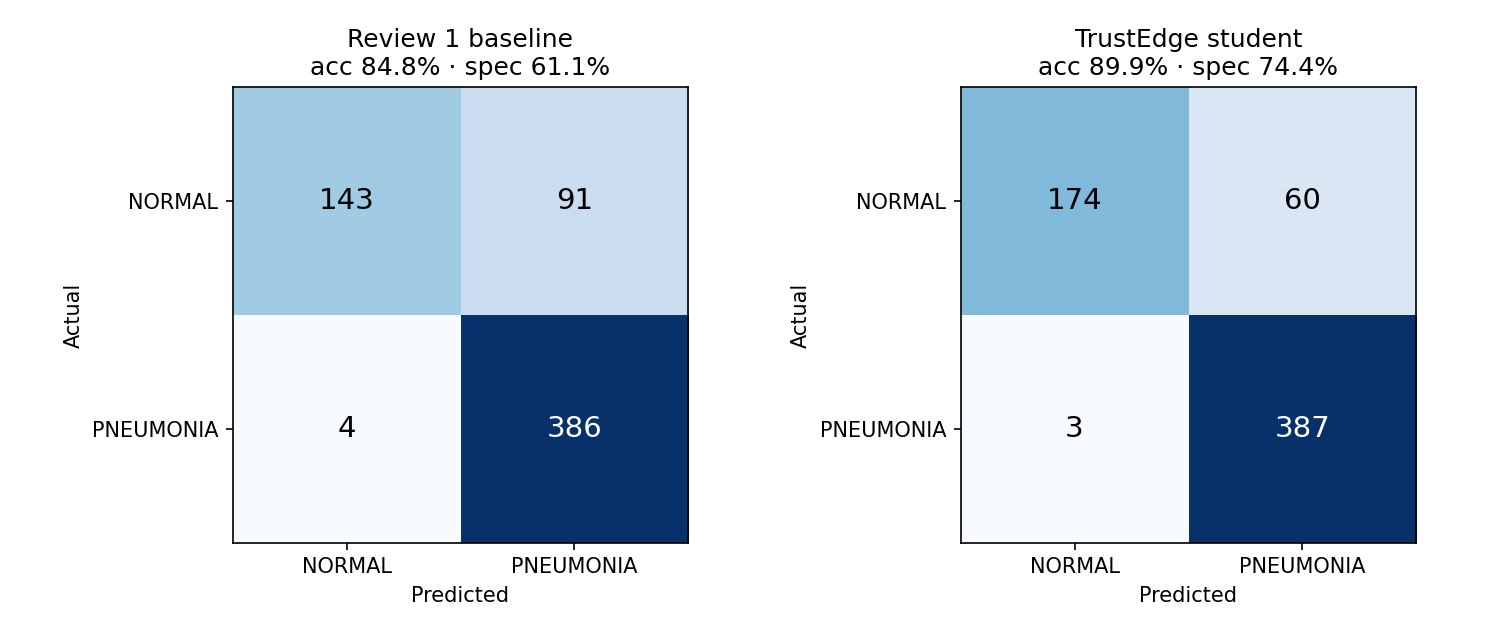

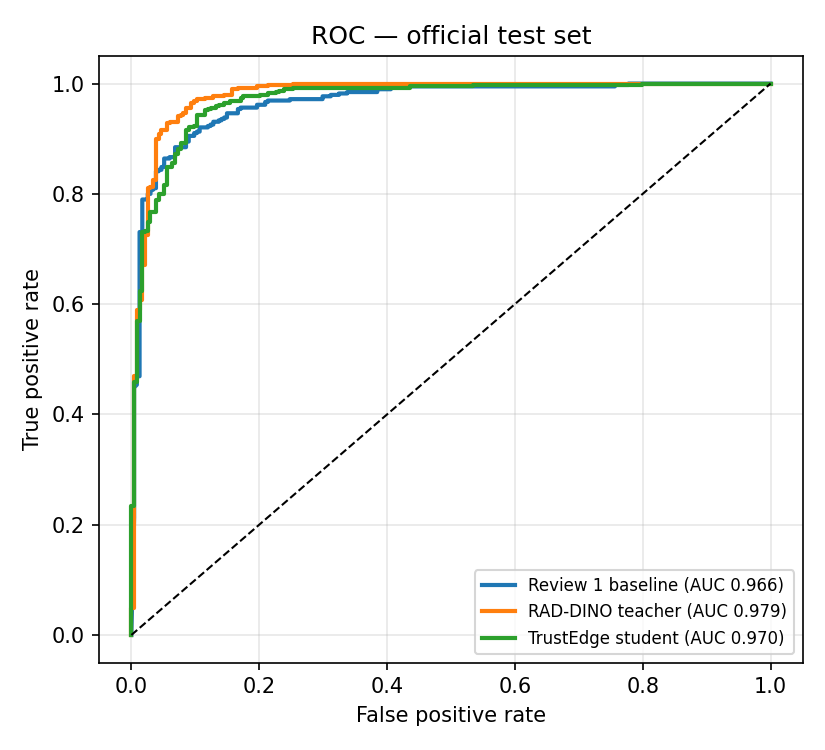

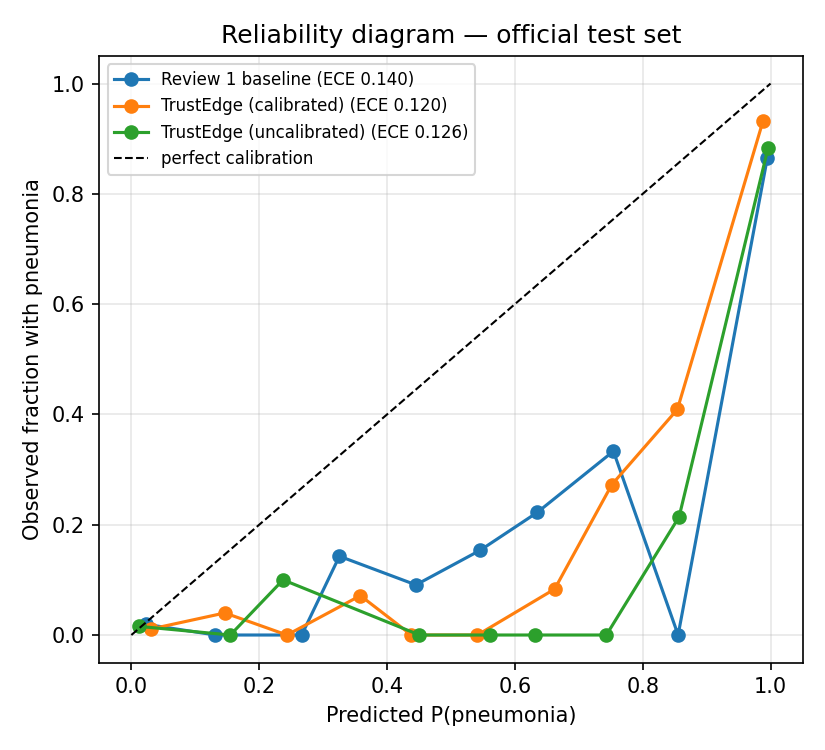

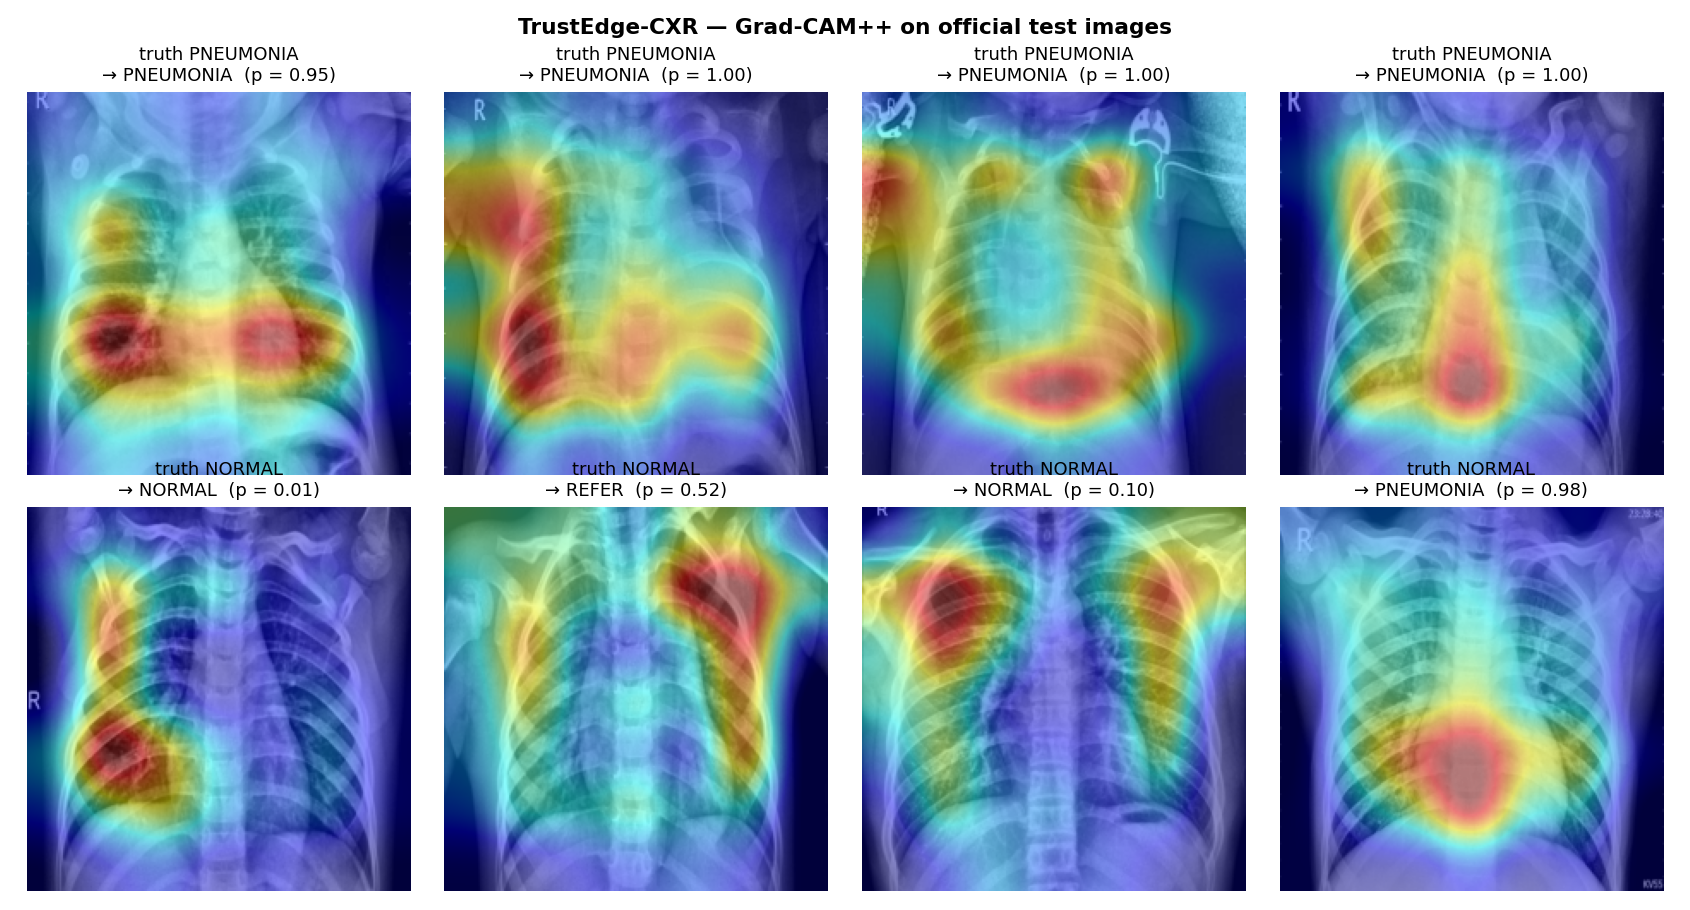

In [37]:
# ── Results ──────────────────────────────────────────────────────────────────
from IPython.display import Image, Markdown, display
R = f"{PROJECT}/artifacts/results"
display(Markdown(open(f"{R}/comparison.md").read()))
for fig in ("confusion_matrices.png", "roc_curves.png", "reliability.png", "heatmap_examples.png"):
    if os.path.exists(f"{R}/{fig}"):
        display(Image(f"{R}/{fig}", width=900))

In [38]:
# ── Package & download (unzip inside chest-xray-pneumonia/ on your laptop) ────
import zipfile, glob
skip = ("/cache/", "embeddings.npz", "student_savedmodel", ".weights.h5", "/rsna/raw224/", "/rsna/clahe224/")
zip_path = "/content/trustedge_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in glob.glob(f"{PROJECT}/artifacts/**", recursive=True):
        if os.path.isfile(path) and not any(s in path for s in skip):
            z.write(path, os.path.relpath(path, PROJECT))
print(f"{zip_path}: {os.path.getsize(zip_path) / 1e6:.1f} MB")
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    !cp /content/trustedge_results.zip /content/drive/MyDrive/
files.download(zip_path)

/content/trustedge_results.zip: 69.2 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>